# Detekcja Phishingu - Random Forest

Ten notebook zawiera implementację i analizę modelu Random Forest do wykrywania phishingu.

## 1. Import bibliotek i konfiguracja


In [1]:
from pathlib import Path
import os
import sys

start_dir = Path.cwd().resolve()
backend_root = None
for candidate in (start_dir, *start_dir.parents):
    if (candidate / 'utils').is_dir() and (candidate / 'notebooks').is_dir():
        backend_root = candidate
        break
    nested_backend = candidate / 'backend'
    if (nested_backend / 'utils').is_dir() and (nested_backend / 'notebooks').is_dir():
        backend_root = nested_backend
        break

if backend_root is None:
    raise RuntimeError(
        f'Cannot locate backend root from Jupyter working directory: {start_dir}'
    )

notebooks_dir = backend_root / 'notebooks'
os.chdir(notebooks_dir)
if str(backend_root) not in sys.path:
    sys.path.insert(0, str(backend_root))

import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import pickle

import importlib

if 'utils.resource_monitor' in sys.modules:
    importlib.reload(sys.modules['utils.resource_monitor'])

if 'utils.isolated_training' in sys.modules:
    importlib.reload(sys.modules['utils.isolated_training'])
from utils.isolated_training import fit_model_isolated
if 'utils.notebook_plot_style' in sys.modules:
    importlib.reload(sys.modules['utils.notebook_plot_style'])

from utils.notebook_plot_style import (
    plot_sample_probability_prediction,
    plot_training_time_comparison,
    save_comparison_figure,
    feature_count_comparison_rows,
    plot_final_train_test_metric_groups,
    resource_baseline_summary,
    classification_metric_sets,
    remove_dataset_figure,
    DATASET_SUBDIRS,
    dataset_key,
    plot_confusion_matrix,
    plot_parameter_train_validation_error,
    plot_roc_curve,
    plot_feature_ranking,
    plot_resource_usage_separate,
    plot_score_curve,
    save_dataset_figure,
)

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score, learning_curve, validation_curve
from sklearn.tree import plot_tree
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           roc_auc_score, confusion_matrix, log_loss)
from utils.feature_names import get_readable_name
from utils.split_dataset_loader import feature_columns
from utils.threshold_calibration import (
    calibrate_threshold, false_positive_rate, model_selection_score,
    DEFAULT_MAX_FALSE_POSITIVE_RATE, DEFAULT_MIN_RECALL,
)

PLOTS_DIR = backend_root.parent / 'results' / 'url_corpus' / 'plots' / 'random_forest'
MODELS_DIR = "../models/random_forest"
os.makedirs(PLOTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)
DATASET_SUBDIR = DATASET_SUBDIRS
os.makedirs(f'{PLOTS_DIR}/full', exist_ok=True)
os.makedirs(f'{PLOTS_DIR}/optimized', exist_ok=True)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['font.size'] = 12
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['figure.figsize'] = (12, 7)

np.random.seed(42)

print("Biblioteki zostały zaimportowane pomyślnie!")


Biblioteki zostały zaimportowane pomyślnie!


## 2. Wczytanie i eksploracja danych


In [2]:
from utils.split_dataset_loader import (
    build_train_test_data,
    feature_columns,
    load_split_frames,
    print_split_summary,
)

QUALITY_SPLIT_DIR = backend_root / 'data' / 'url_corpus' / 'quality_v4_repaired_features'
split_frames = {
    'Pełny zbiór': load_split_frames(QUALITY_SPLIT_DIR, 'dataset_full'),
    'Zoptymalizowany zbiór': load_split_frames(QUALITY_SPLIT_DIR, 'dataset_optimized'),
}
print_split_summary(split_frames)
datasets = split_frames


DANE ZAŁADOWANE - PREDEFINED DOMAIN/TEMPLATE SPLITS

Pełny zbiór:
  • train: 108,762 rows, 110 features, safe=54,381, phishing=54,381
  • val: 21,676 rows, 110 features, safe=10,838, phishing=10,838
  • test: 21,000 rows, 110 features, safe=10,500, phishing=10,500

Zoptymalizowany zbiór:
  • train: 108,762 rows, 47 features, safe=54,381, phishing=54,381
  • val: 21,676 rows, 47 features, safe=10,838, phishing=10,838
  • test: 21,000 rows, 47 features, safe=10,500, phishing=10,500

Uwaga: zbiory URL-corpus są celowo zbalansowane (50% bezpiecznych, 50% phishingowych) na potrzeby kontrolowanego porównania algorytmów.
Wyników precision i accuracy nie należy bezpośrednio interpretować jako częstości błędów w ruchu produkcyjnym.

No random train_test_split is used for URL corpus notebooks.


## 3. Przygotowanie cech i etykiet


In [3]:
data_splits = {}

for name, frames in datasets.items():
    train_df = frames['train']
    model_feature_columns = feature_columns(train_df)
    train_class_counts = train_df['phishing'].value_counts()
    positive_count = int(train_class_counts.get(1, 0))
    if positive_count == 0:
        raise ValueError(f'Brak klasy phishing w treningowym splicie: {name}')
    scale_pos_weight = float(train_class_counts.get(0, 0) / positive_count)

    data_splits[name] = {
        'frames': frames,
        'X': train_df[model_feature_columns],
        'y': train_df['phishing'],
        'feature_columns': model_feature_columns,
        'feature_count': len(model_feature_columns),
        'scale_pos_weight': scale_pos_weight,
    }

    print(f"\n{name}:")
    print(f"  • Liczba cech: {len(model_feature_columns)}")
    for split_name, df in frames.items():
        counts = df['phishing'].value_counts()
        print(f"  • {split_name}: {len(df):,} próbek")
        print(f"    - Legalny URL: {counts.get(0, 0):,}")
        print(f"    - Phishing: {counts.get(1, 0):,}")



Pełny zbiór:
  • Liczba cech: 110
  • train: 108,762 próbek
    - Legalny URL: 54,381
    - Phishing: 54,381
  • val: 21,676 próbek
    - Legalny URL: 10,838
    - Phishing: 10,838
  • test: 21,000 próbek
    - Legalny URL: 10,500
    - Phishing: 10,500

Zoptymalizowany zbiór:
  • Liczba cech: 47
  • train: 108,762 próbek
    - Legalny URL: 54,381
    - Phishing: 54,381
  • val: 21,676 próbek
    - Legalny URL: 10,838
    - Phishing: 10,838
  • test: 21,000 próbek
    - Legalny URL: 10,500
    - Phishing: 10,500


## 4. Podział danych na zbiory uczący i testowy


In [4]:
from sklearn.preprocessing import StandardScaler

train_test_data = build_train_test_data(datasets)

for name, data in train_test_data.items():
    X_train = data['X_train']
    X_val = data['X_val']
    X_test = data['X_test']
    y_train = data['y_train']
    y_val = data['y_val']
    y_test = data['y_test']

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    data_splits[name]['X'] = X_train
    data_splits[name]['y'] = y_train
    data_splits[name]['X_train'] = X_train
    data_splits[name]['X_val'] = X_val
    data_splits[name]['X_test'] = X_test
    data_splits[name]['y_train'] = y_train
    data_splits[name]['y_val'] = y_val
    data_splits[name]['y_test'] = y_test
    data_splits[name]['X_train_scaled'] = X_train_scaled
    data_splits[name]['X_val_scaled'] = X_val_scaled
    data_splits[name]['X_test_scaled'] = X_test_scaled
    data_splits[name]['scaler'] = scaler

    print(f"\n{name}:")
    print(f"  • Zbiór uczący: {X_train.shape[0]:,} próbek")
    print(f"  • Zbiór do testowania podczas uczenia: {X_val.shape[0]:,} próbek")
    print(f"  • Końcowy zbiór testowy: {X_test.shape[0]:,} próbek")
    print("  • Podział pochodzi z plików quality_v4_repaired_features; train_test_split nie jest używany.")

    train_counts = y_train.value_counts()
    print(f"  • Rozkład klas (uczący):")
    print(f"    - Legalny URL: {train_counts.get(0, 0):,}")
    print(f"    - Phishing: {train_counts.get(1, 0):,}")



Pełny zbiór:
  • Zbiór uczący: 108,762 próbek
  • Zbiór do testowania podczas uczenia: 21,676 próbek
  • Końcowy zbiór testowy: 21,000 próbek
  • Podział pochodzi z plików quality_v4_repaired_features; train_test_split nie jest używany.
  • Rozkład klas (uczący):
    - Legalny URL: 54,381
    - Phishing: 54,381

Zoptymalizowany zbiór:
  • Zbiór uczący: 108,762 próbek
  • Zbiór do testowania podczas uczenia: 21,676 próbek
  • Końcowy zbiór testowy: 21,000 próbek
  • Podział pochodzi z plików quality_v4_repaired_features; train_test_split nie jest używany.
  • Rozkład klas (uczący):
    - Legalny URL: 54,381
    - Phishing: 54,381


## 5. Optymalizacja hiperparametrów i trening modelu


In [5]:
param_grids = [
    {
        'name': 'Optymalizacja liczby drzew',
        'params': {
            'n_estimators': [100, 200, 300],
            'max_depth': [None],
            'min_samples_split': [2],
            'min_samples_leaf': [1],
            'max_features': ['sqrt'],
            'class_weight': [None, 'balanced', 'balanced_subsample']
        }
    },
    {
        'name': 'Optymalizacja głębokości',
        'params': {
            'n_estimators': [200],
            'max_depth': [10, 20, 30, None],
            'min_samples_split': [2],
            'min_samples_leaf': [1],
            'max_features': ['sqrt'],
            'class_weight': [None, 'balanced', 'balanced_subsample']
        }
    },
    {
        'name': 'Optymalizacja podziału węzłów',
        'params': {
            'n_estimators': [200],
            'max_depth': [None],
            'min_samples_split': [2, 5, 10],
            'min_samples_leaf': [1, 2, 4],
            'max_features': ['sqrt'],
            'class_weight': [None, 'balanced', 'balanced_subsample']
        }
    }
]

trained_models = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"OPTYMALIZACJA HIPERPARAMETRÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train = data['X_train']
    y_train = data['y_train']

    best_overall_score = 0
    best_overall_params = None
    best_config_name = ""

    start_time = time.time()

    for i, grid_config in enumerate(param_grids):
        config_name = grid_config['name']
        param_grid = grid_config['params']

        combinations = (len(param_grid['n_estimators']) *
                       len(param_grid['max_depth']) *
                       len(param_grid['min_samples_split']) *
                       len(param_grid['min_samples_leaf']) *
                       len(param_grid['max_features']) *
                       len(param_grid['class_weight']))

        print(f"\nKonfiguracja {i+1}/{len(param_grids)}: {config_name}")
        print(f"Testowanie {combinations} kombinacji parametrów...")

        config_start_time = time.time()

        grid_search = GridSearchCV(
            RandomForestClassifier(random_state=42, n_jobs=-1),
            param_grid,
            cv=5,
            scoring=model_selection_score,
            n_jobs=-1,
            verbose=0
        )

        grid_search.fit(X_train, y_train)

        config_time = time.time() - config_start_time

        print(f"  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): {grid_search.best_score_:.4f}")
        print(f"  • Czas: {config_time:.2f}s")

        if grid_search.best_score_ > best_overall_score:
            best_overall_score = grid_search.best_score_
            best_overall_params = grid_search.best_params_
            best_config_name = config_name

    optimization_time = time.time() - start_time

    print(f"\n{'-'*80}")
    print(f"WYNIKI OPTYMALIZACJI - {dataset_name}:")
    print(f"  • Całkowity czas optymalizacji: {optimization_time:.2f}s ({optimization_time/60:.1f} min)")
    print(f"  • Najlepszy wynik CV funkcji kalibracyjnej: {best_overall_score:.4f}")
    print(f"  • Najlepsza konfiguracja: {best_config_name}")
    print(f"  • Najlepsze parametry: {best_overall_params}")

    trained_models[dataset_name] = {
        'params': best_overall_params,
        'cv_score': best_overall_score,
        'config_name': best_config_name,
        'optimization_time': optimization_time
    }

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW OPTYMALIZACJI")
print(f"{'='*80}")
for name, results in trained_models.items():
    print(f"\n{name}:")
    print(f"  • CV wynik funkcji kalibracyjnej: {results['cv_score']:.4f}")
    print(f"  • Czas optymalizacji: {results['optimization_time']:.2f}s")


OPTYMALIZACJA HIPERPARAMETRÓW - PEŁNY ZBIÓR

Konfiguracja 1/3: Optymalizacja liczby drzew
Testowanie 9 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.2230
  • Czas: 1017.79s

Konfiguracja 2/3: Optymalizacja głębokości
Testowanie 12 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.2228
  • Czas: 999.11s

Konfiguracja 3/3: Optymalizacja podziału węzłów
Testowanie 27 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.2228
  • Czas: 298.45s

--------------------------------------------------------------------------------
WYNIKI OPTYMALIZACJI - Pełny zbiór:
  • Całkowity czas optymalizacji: 2315.36s (38.6 min)
  • Najlepszy wynik CV funkcji kalibracyjnej: 1.2230
  • Najlepsza konfiguracja: Optymalizacja liczby drzew
  • Najlepsze parametry: {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

OPTYMALIZACJA HIPERPARAMETRÓW - ZOPTYMALIZOWANY ZBIÓR

Konfiguracja 1/3: Optymalizacja liczby drzew
Testowanie 9 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.2229
  • Czas: 1002.63s

Konfiguracja 2/3: Optymalizacja głębokości
Testowanie 12 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.2228
  • Czas: 1010.82s

Konfiguracja 3/3: Optymalizacja podziału węzłów
Testowanie 27 kombinacji parametrów...


  • Najlepszy wynik funkcji kalibracyjnej (AUC + recall - FPR): 1.2228
  • Czas: 431.66s

--------------------------------------------------------------------------------
WYNIKI OPTYMALIZACJI - Zoptymalizowany zbiór:
  • Całkowity czas optymalizacji: 2445.11s (40.8 min)
  • Najlepszy wynik CV funkcji kalibracyjnej: 1.2229
  • Najlepsza konfiguracja: Optymalizacja liczby drzew
  • Najlepsze parametry: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}

PORÓWNANIE WYNIKÓW OPTYMALIZACJI

Pełny zbiór:
  • CV wynik funkcji kalibracyjnej: 1.2230
  • Czas optymalizacji: 2315.36s

Zoptymalizowany zbiór:
  • CV wynik funkcji kalibracyjnej: 1.2229
  • Czas optymalizacji: 2445.11s


## 5.1. Trening i monitorowanie zasobów systemowych (RAM i CPU)


In [6]:
resource_stats = {}

for dataset_name, data in train_test_data.items():
    print(f"\n{'='*80}")
    print(f"TRENING MODELU Z MONITOROWANIEM ZASOBÓW - {dataset_name.upper()}")
    print(f"{'='*80}")

    X_train = data['X_train']
    y_train = data['y_train']

    print(f"Trenowanie na pełnym zbiorze uczącym: {X_train.shape[0]} próbek, {X_train.shape[1]} cech")

    best_params = trained_models[dataset_name]['params']

    model = RandomForestClassifier(random_state=42, n_jobs=-1, **best_params)
    isolated_result = fit_model_isolated(
        model, X_train, y_train, interval=0.05,
    )
    model = isolated_result.model
    monitor = isolated_result.monitor
    training_time = isolated_result.training_time
    stats = isolated_result.stats

    resource_stats[dataset_name] = {
        'monitor': monitor,
        'stats': stats
    }

    trained_models[dataset_name]['model'] = model
    trained_models[dataset_name]['training_time'] = training_time

    print(f"\n{'-'*80}")
    print(f"WYNIKI TRENINGU - {dataset_name}:")
    print(f"  • Czas treningu: {training_time:.2f}s")
    print(f"  • Liczba próbek monitorowania: {stats['samples']}")
    print(f"  • CPU:")
    print(f"    - Min: {stats['cpu']['min']:.1f}%")
    print(f"    - Max: {stats['cpu']['max']:.1f}%")
    print(f"    - Średnia: {stats['cpu']['mean']:.1f}%")
    print(f"  • RAM:")
    print(f"    - Min: {stats['ram']['min']:.2f} GB")
    print(f"    - Max: {stats['ram']['max']:.2f} GB")
    print(f"    - Średnia: {stats['ram']['mean']:.2f} GB")


TRENING MODELU Z MONITOROWANIEM ZASOBÓW - PEŁNY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 108762 próbek, 110 cech



--------------------------------------------------------------------------------
WYNIKI TRENINGU - Pełny zbiór:
  • Czas treningu: 4.46s
  • Liczba próbek monitorowania: 70
  • CPU:
    - Min: 8.5%
    - Max: 100.8%
    - Średnia: 71.9%
  • RAM:
    - Min: 0.27 GB
    - Max: 0.83 GB
    - Średnia: 0.65 GB

TRENING MODELU Z MONITOROWANIEM ZASOBÓW - ZOPTYMALIZOWANY ZBIÓR
Trenowanie na pełnym zbiorze uczącym: 108762 próbek, 47 cech



--------------------------------------------------------------------------------
WYNIKI TRENINGU - Zoptymalizowany zbiór:
  • Czas treningu: 2.89s
  • Liczba próbek monitorowania: 46
  • CPU:
    - Min: 8.4%
    - Max: 100.6%
    - Średnia: 87.8%
  • RAM:
    - Min: 0.23 GB
    - Max: 0.65 GB
    - Średnia: 0.51 GB


## 5.2. Wizualizacja wykorzystania zasobów systemowych


Poziom bazowy to mediana 7 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,06% łącznej mocy 11 rdzeni logicznych; RAM: 0,27 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


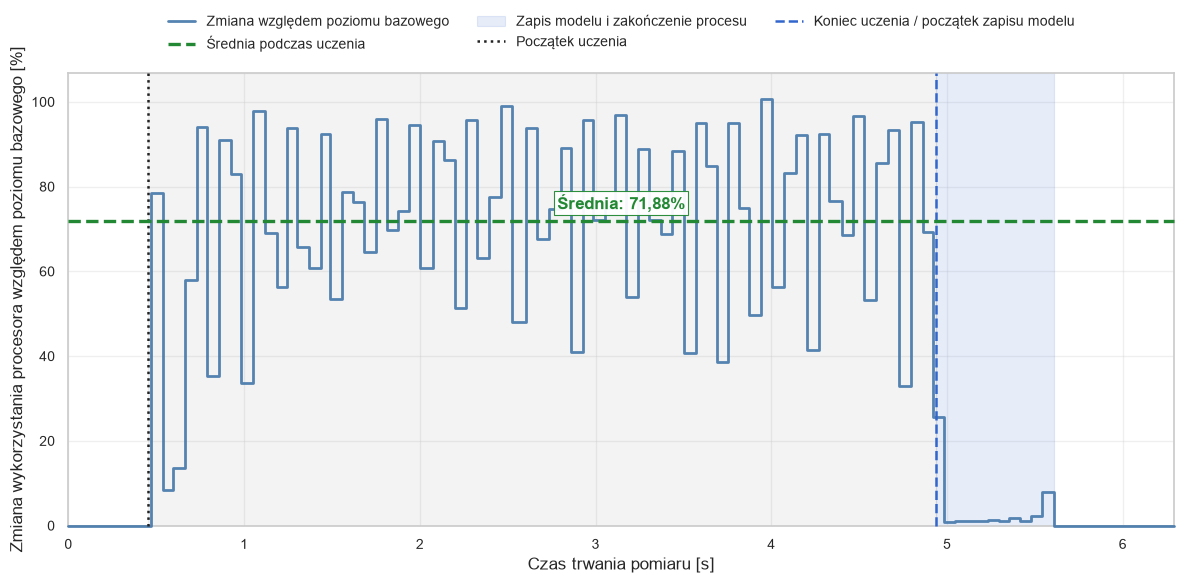

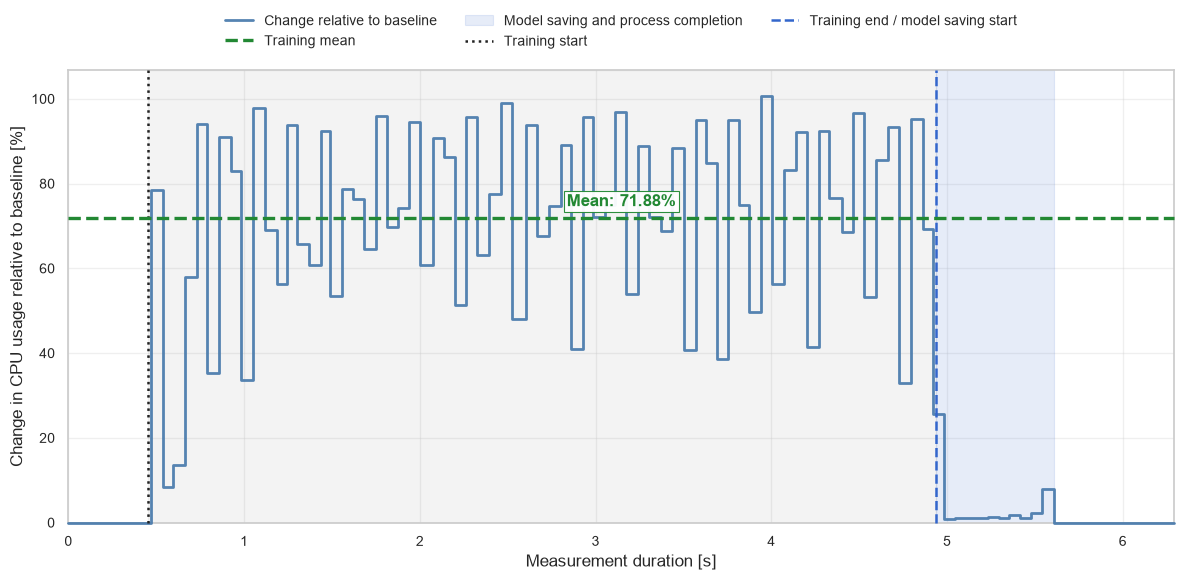

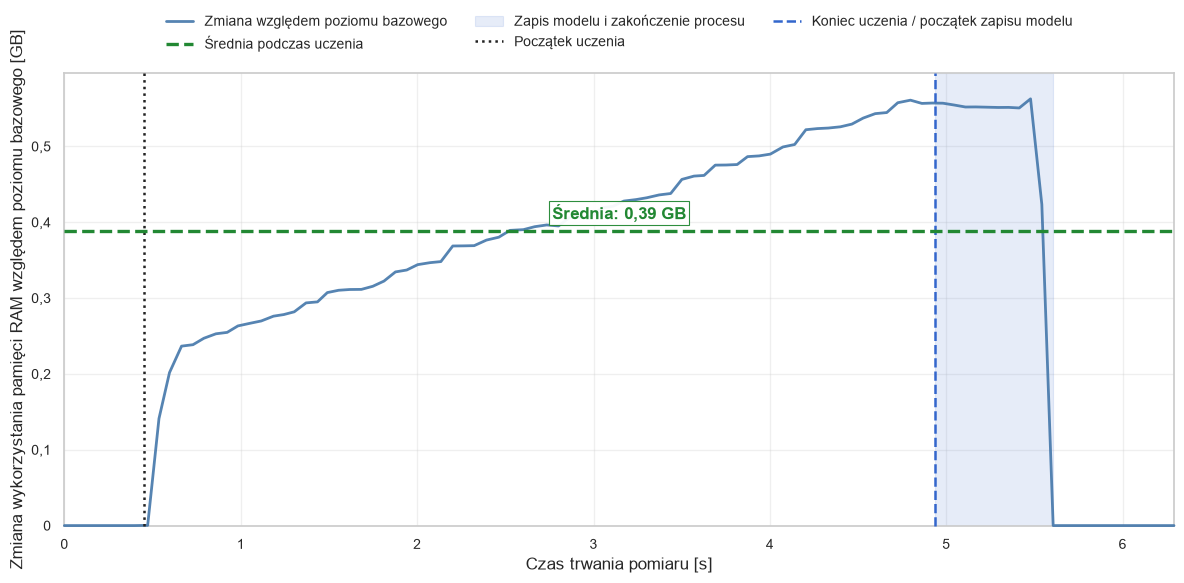

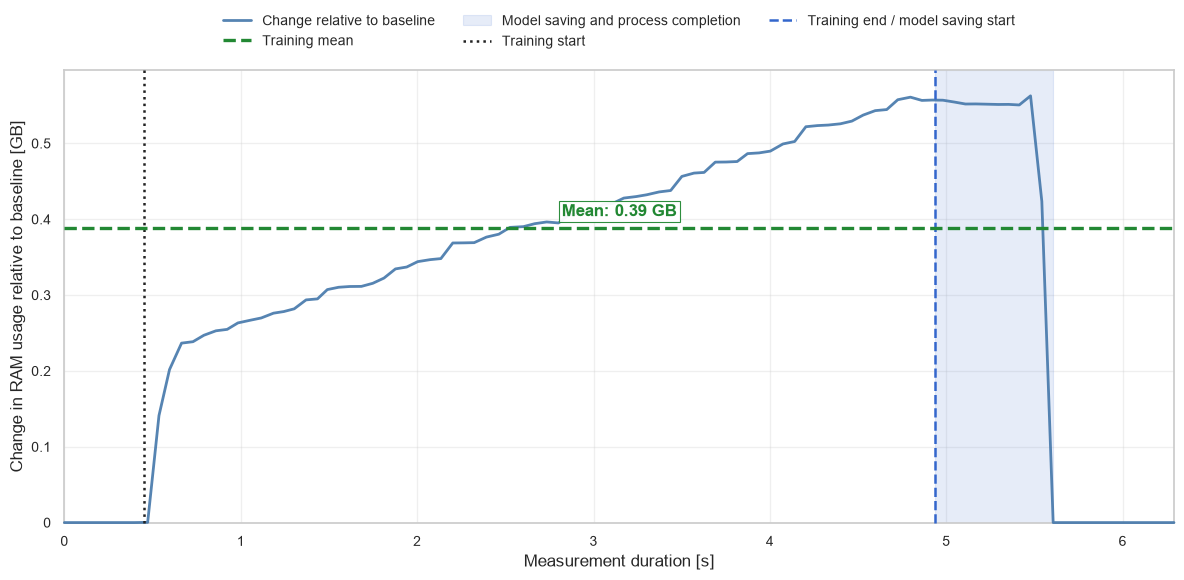

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/resource_usage/random_forest_full.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/random_forest/full/pl/random_forest_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/random_forest/full/pl/random_forest_resource_usage_ram.png


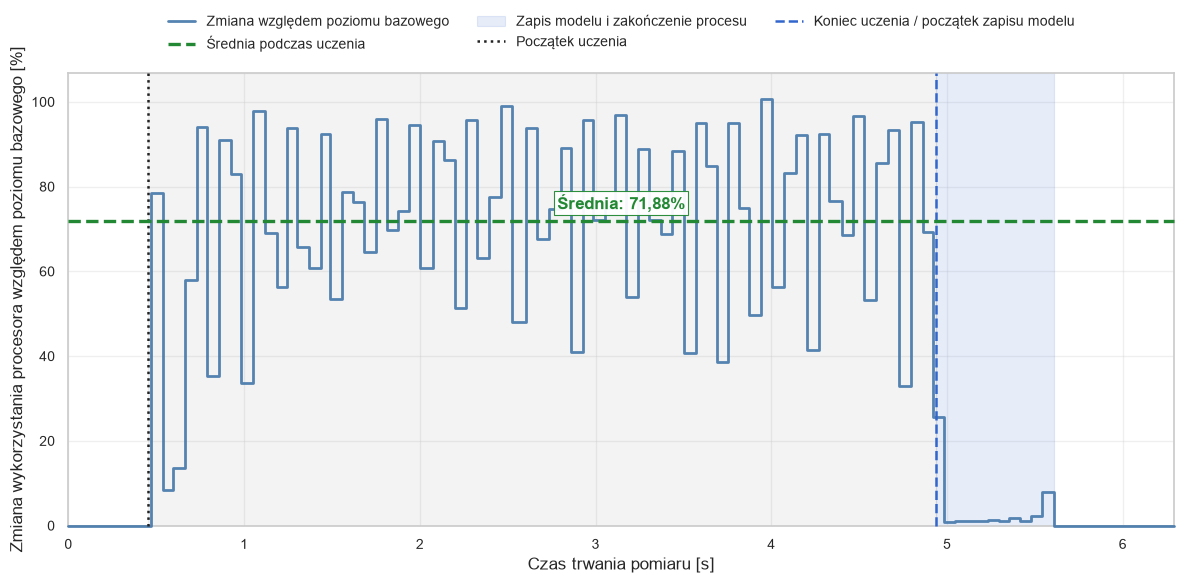

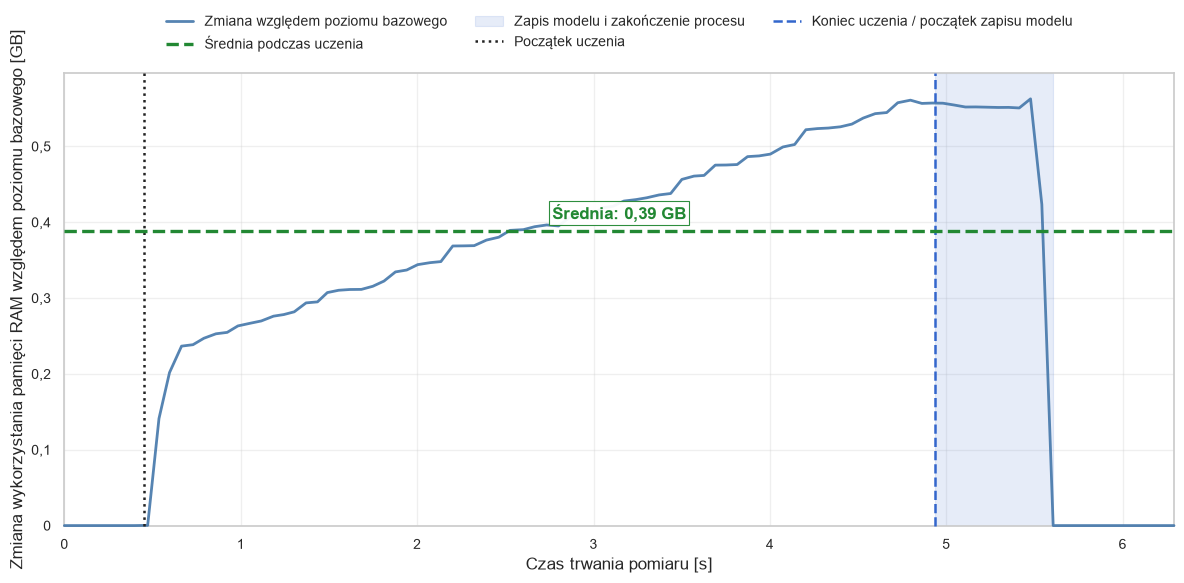

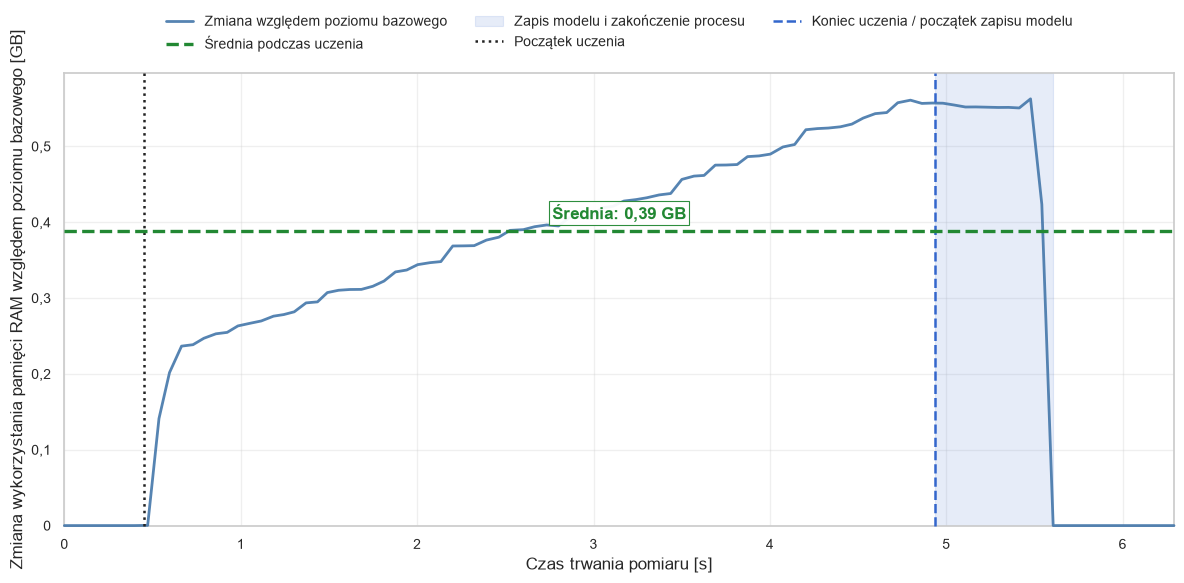

Poziom bazowy to mediana 7 próbek procesu izolowanego i jego procesów potomnych, zebranych bezpośrednio przed uczeniem (CPU: 0,06% łącznej mocy 11 rdzeni logicznych; RAM: 0,21 GB). Wykres przedstawia nieujemną różnicę: pomiar minus poziom bazowy.


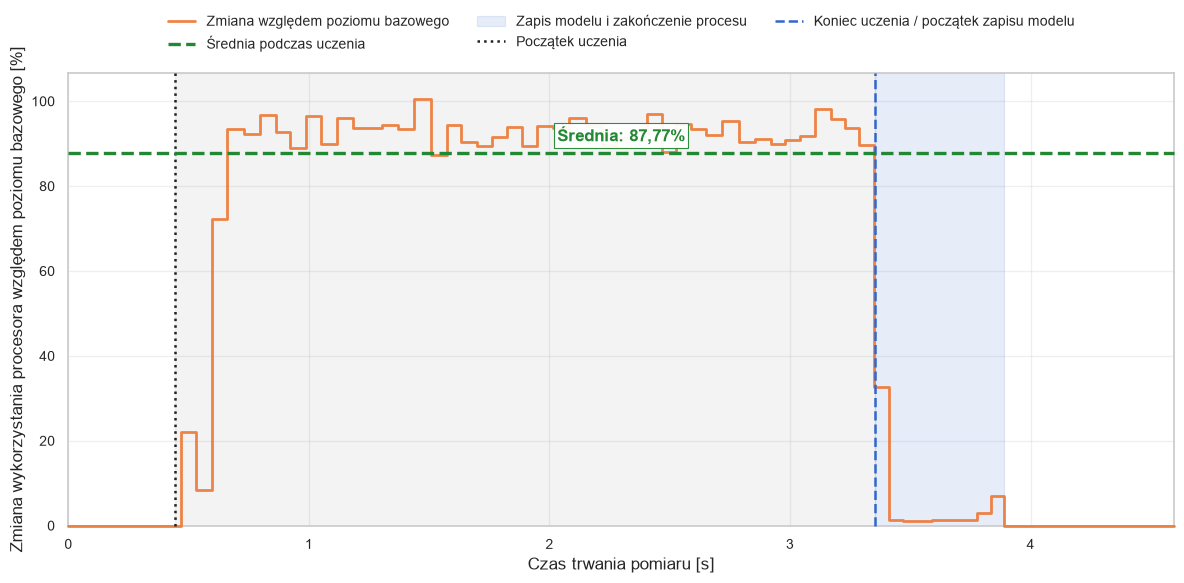

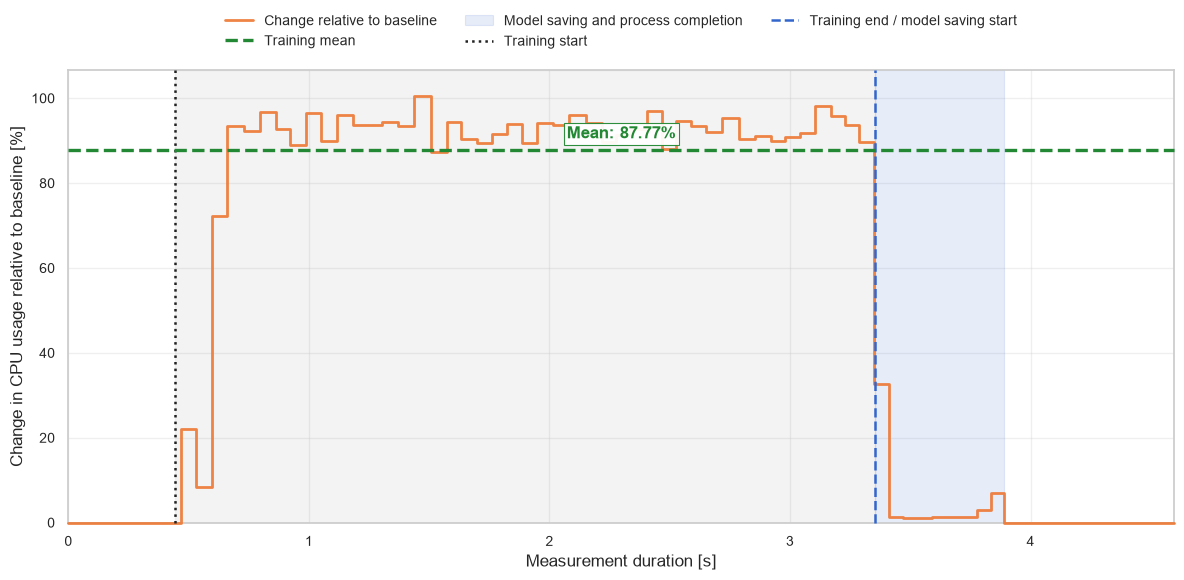

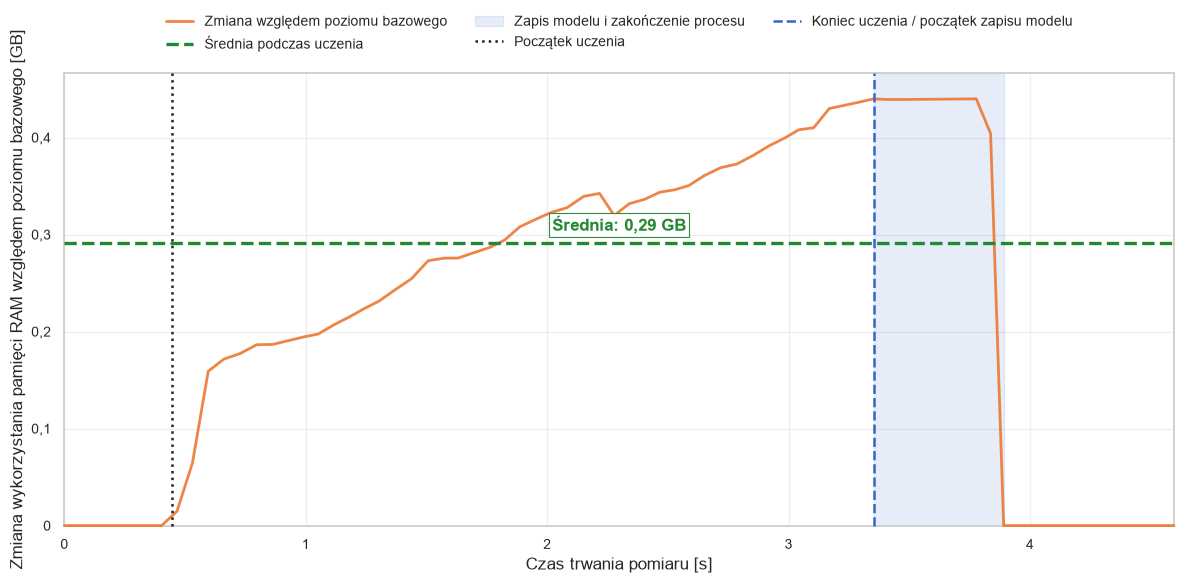

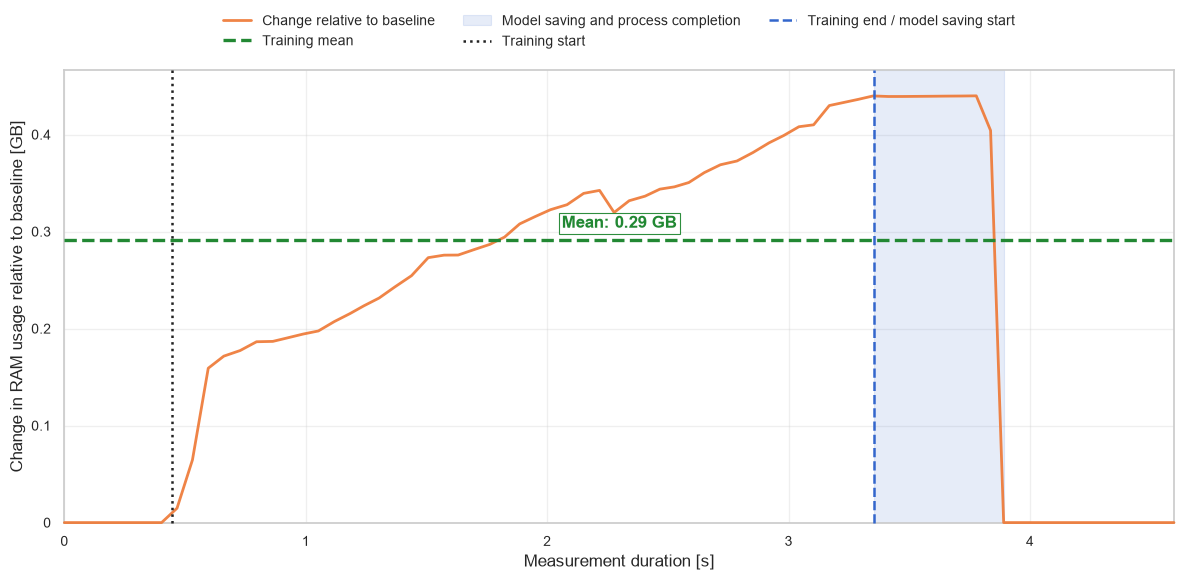

Zapisano ślad: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/resource_usage/random_forest_optimized.csv
Zapisano wykres CPU: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/random_forest/optimized/pl/random_forest_resource_usage_cpu.png
Zapisano wykres RAM: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/random_forest/optimized/pl/random_forest_resource_usage_ram.png


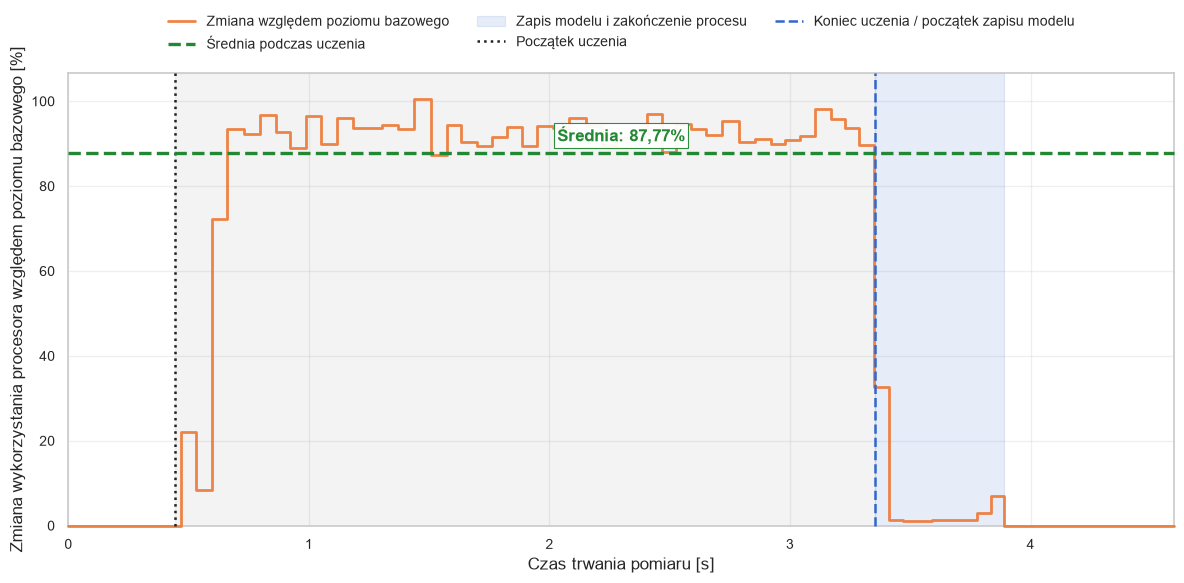

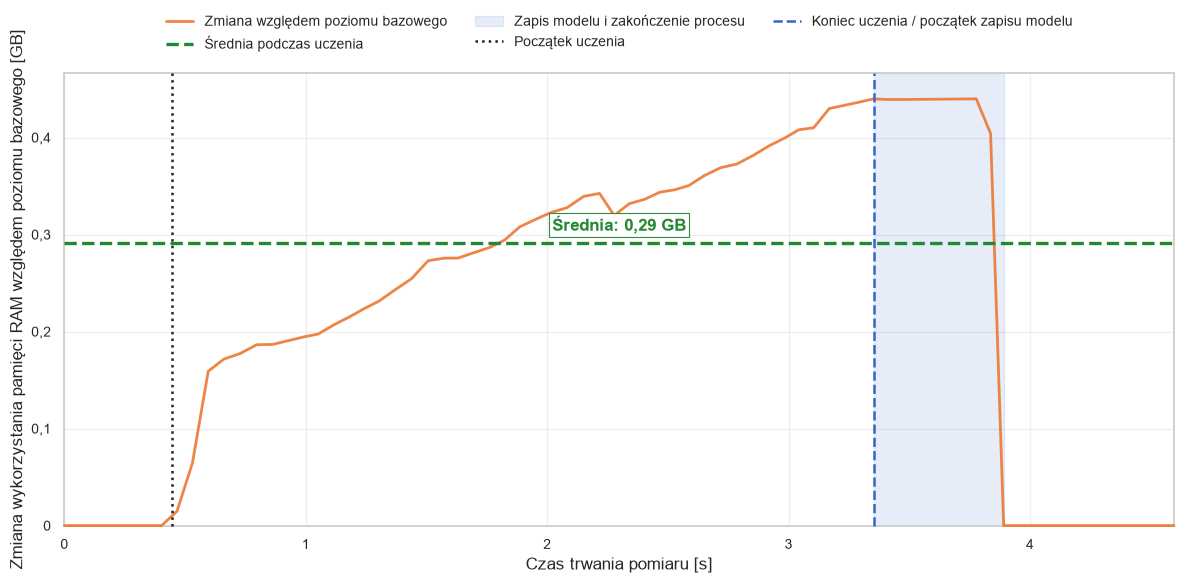

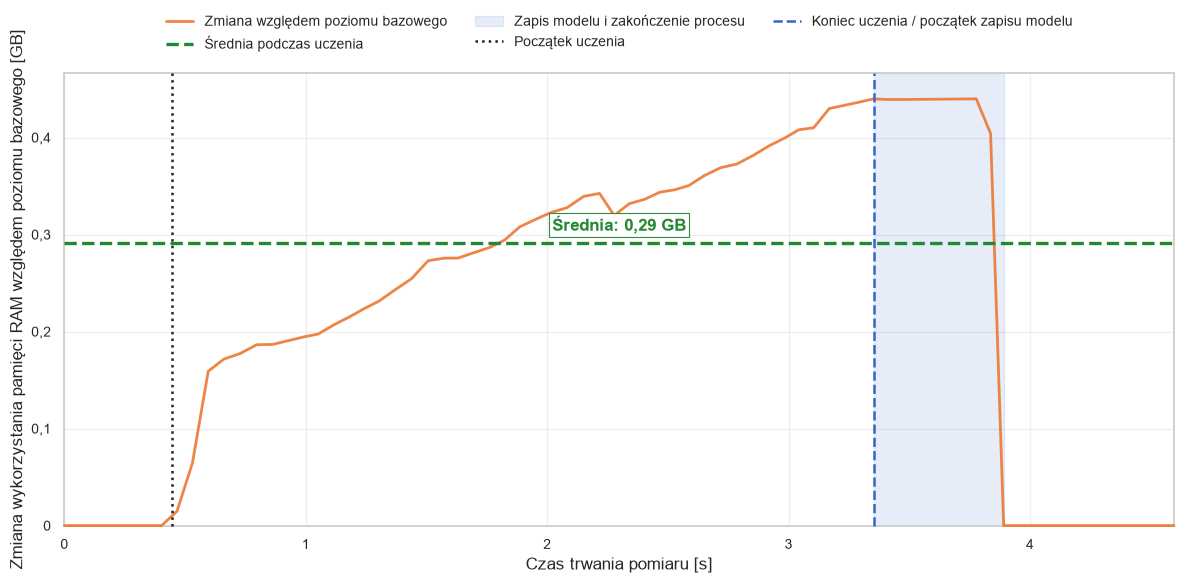

In [7]:
from IPython.display import display

for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    monitor = resource_stats[dataset_name]['monitor']
    stats = resource_stats[dataset_name]['stats']
    print(resource_baseline_summary(monitor))
    trace_dir = backend_root.parent / 'results' / 'url_corpus' / 'resource_usage'
    trace_dir.mkdir(parents=True, exist_ok=True)
    trace_path = trace_dir / f'random_forest_{dataset_key(dataset_name)}.csv'
    monitor.save_phase_trace(trace_path)
    cpu_figure, ram_figure = plot_resource_usage_separate(monitor, stats, dataset_name, include_post_training=True)
    cpu_path = save_dataset_figure(cpu_figure, PLOTS_DIR, dataset_name, 'random_forest_resource_usage_cpu.png')
    ram_path = save_dataset_figure(ram_figure, PLOTS_DIR, dataset_name, 'random_forest_resource_usage_ram.png')
    print(f'Zapisano ślad: {trace_path}')
    print(f'Zapisano wykres CPU: {cpu_path}')
    print(f'Zapisano wykres RAM: {ram_path}')
    display(cpu_figure)
    display(ram_figure)
    plt.close(cpu_figure)
    plt.close(ram_figure)
    plt.show()


## 6. Porównanie wyników uczenia i testowania

Miary dla procesu uczenia obliczane są na zbiorze uczącym, a miary testowe na
niezależnym zbiorze testowym. Każda miara jest prezentowana na osobnym wykresie
i wykorzystuje wyniki uzyskane przez wytrenowany model, bez jego ponownego
uczenia na potrzeby wizualizacji.

Walidacja oznacza ocenę modelu na danych, które nie uczestniczyły w jego
dopasowaniu w danym przebiegu, ale nadal należą do części danych przeznaczonej
do opracowania modelu. Nie jest ona testem końcowym. Dla każdego rozmiaru
podzbioru uczącego linia uczenia i linia walidacji przedstawiają średnią z pięciu
przebiegów, a półprzezroczyste pasmo przedstawia jedno odchylenie standardowe.
Niezależny zbiór testowy nie uczestniczy w wyznaczaniu tych krzywych.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.



EWALUACJA MODELU - PEŁNY ZBIÓR



WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9011
  • Precyzja: 0.9741
  • Czułość: 0.8242
  • Współczynnik fałszywie dodatnich (FPR): 0.0219 (2.19%)
  • Próg skalibrowany na walidacji: 0.6001
  • Walidacyjny FPR przy wybranym progu: 1.97%
  • Walidacyjna czułość przy wybranym progu: 86.34%
  • Docelowy FPR kalibracji: 2.00%
  • Miara F1 (F1-Score): 0.8929
  • AUC-ROC: 0.9793
  • Błąd uczenia: 0.0015
  • Błąd testowania: 0.0989


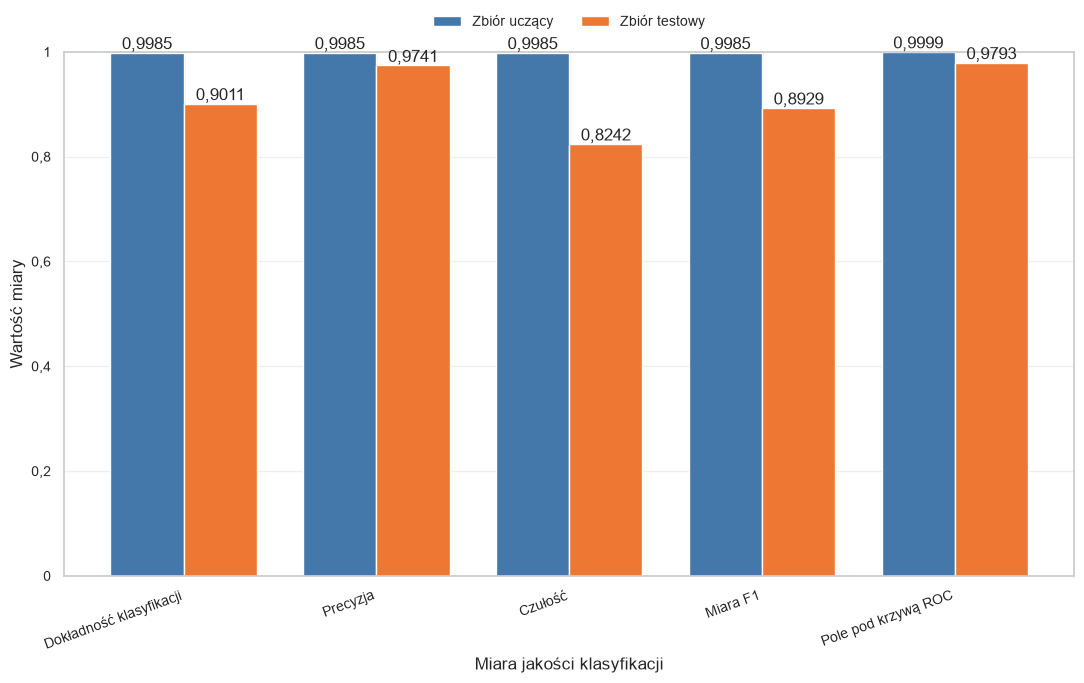

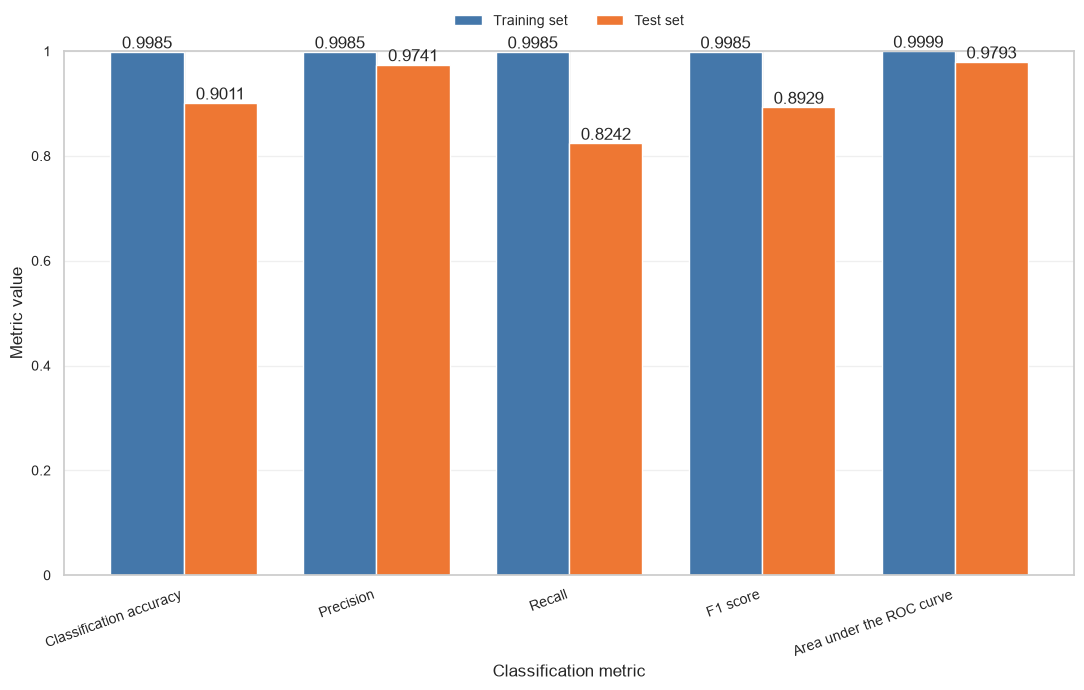

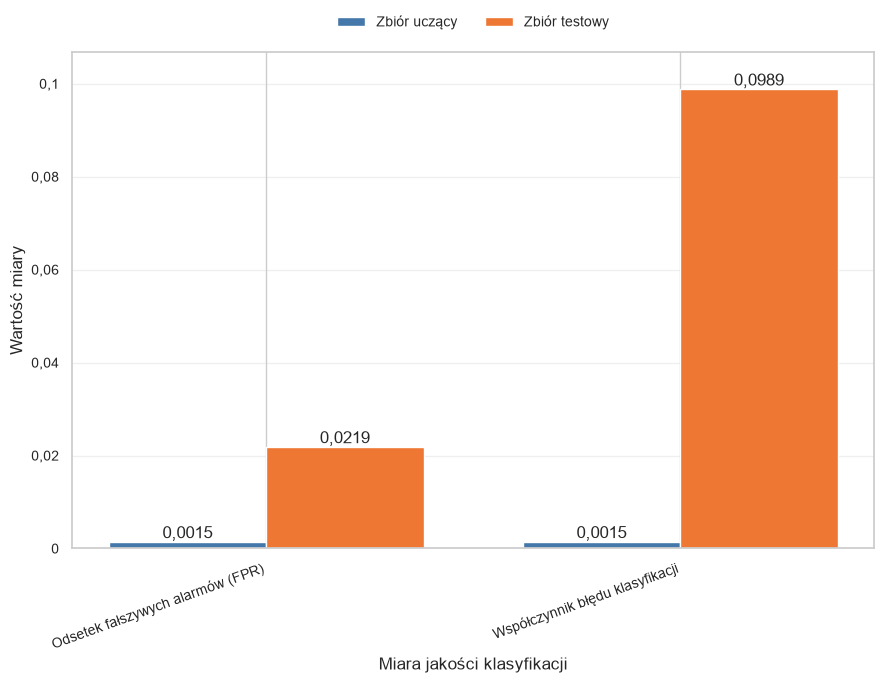

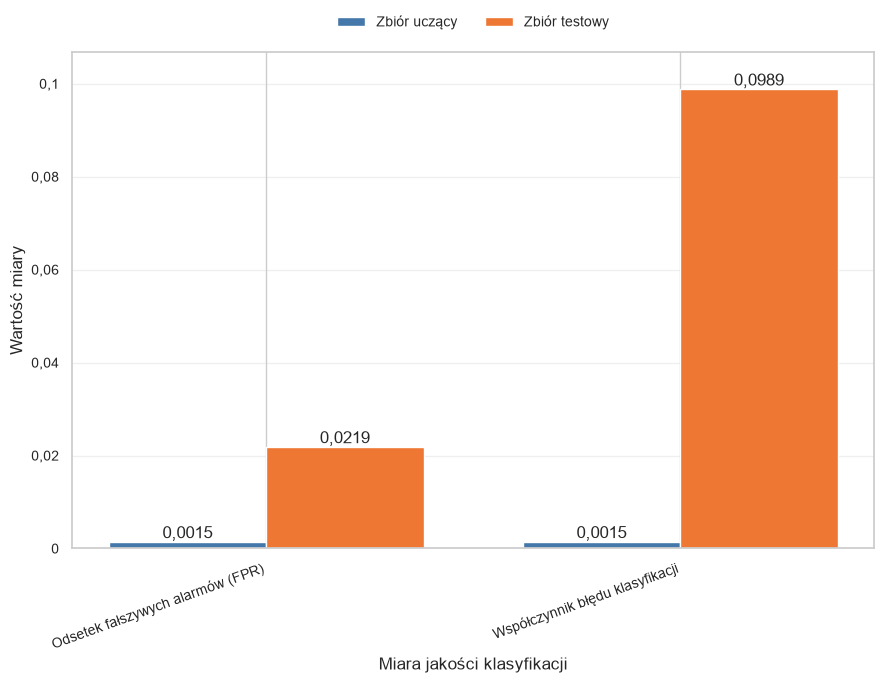

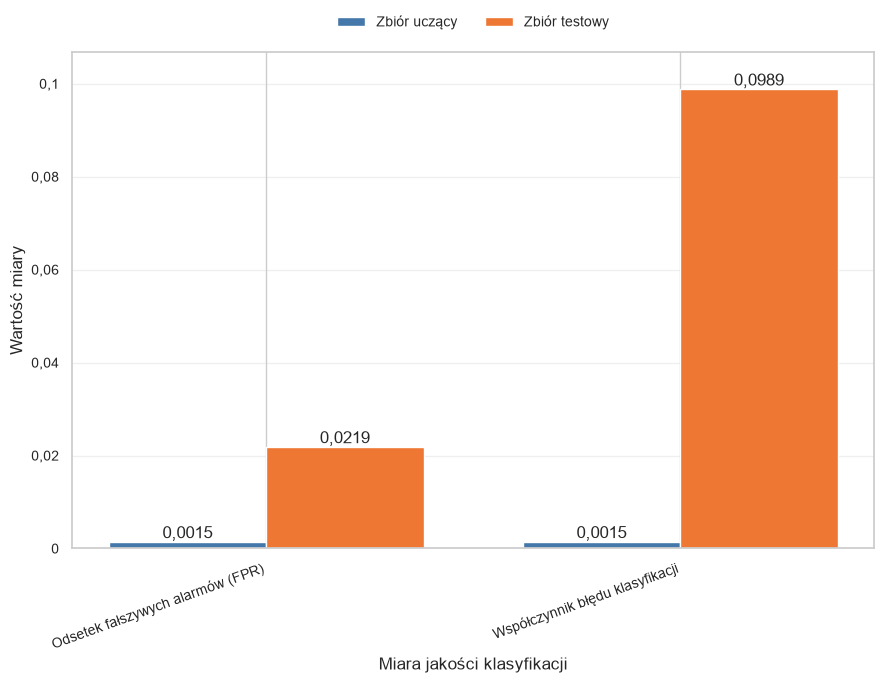

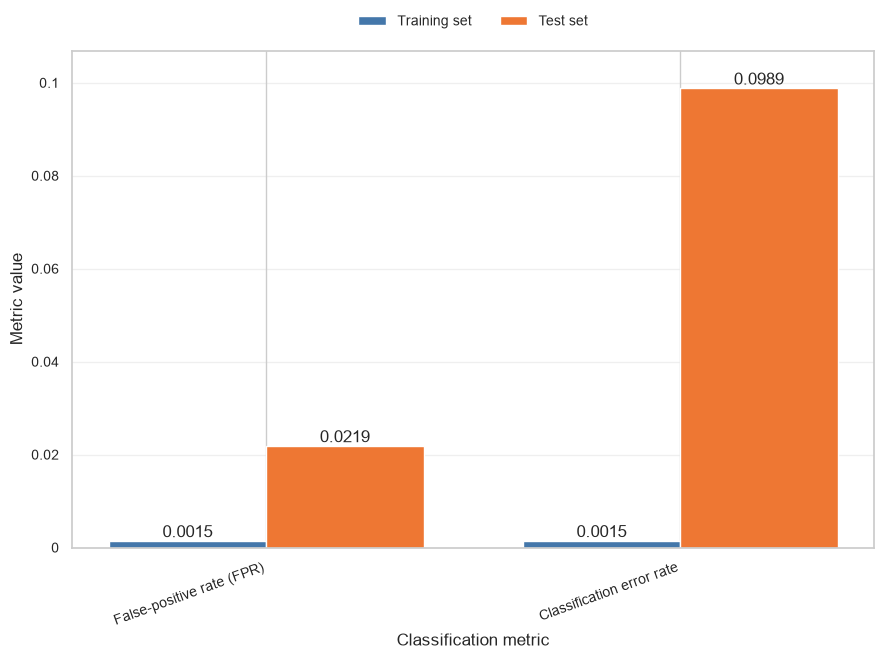


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 10,270
  • Fałszywie pozytywne (FP): 230
  • Fałszywie negatywne (FN): 1,846
  • Prawdziwie pozytywne (TP): 8,654

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9944 ± 0.0003
  • Min: 0.9939
  • Max: 0.9947

EWALUACJA MODELU - ZOPTYMALIZOWANY ZBIÓR



WYNIKI NA ZBIORZE TESTOWYM:
  • Dokładność (Accuracy): 0.9031
  • Precyzja: 0.9754
  • Czułość: 0.8270
  • Współczynnik fałszywie dodatnich (FPR): 0.0209 (2.09%)
  • Próg skalibrowany na walidacji: 0.6067
  • Walidacyjny FPR przy wybranym progu: 1.98%
  • Walidacyjna czułość przy wybranym progu: 86.27%
  • Docelowy FPR kalibracji: 2.00%
  • Miara F1 (F1-Score): 0.8951
  • AUC-ROC: 0.9806
  • Błąd uczenia: 0.0016
  • Błąd testowania: 0.0969


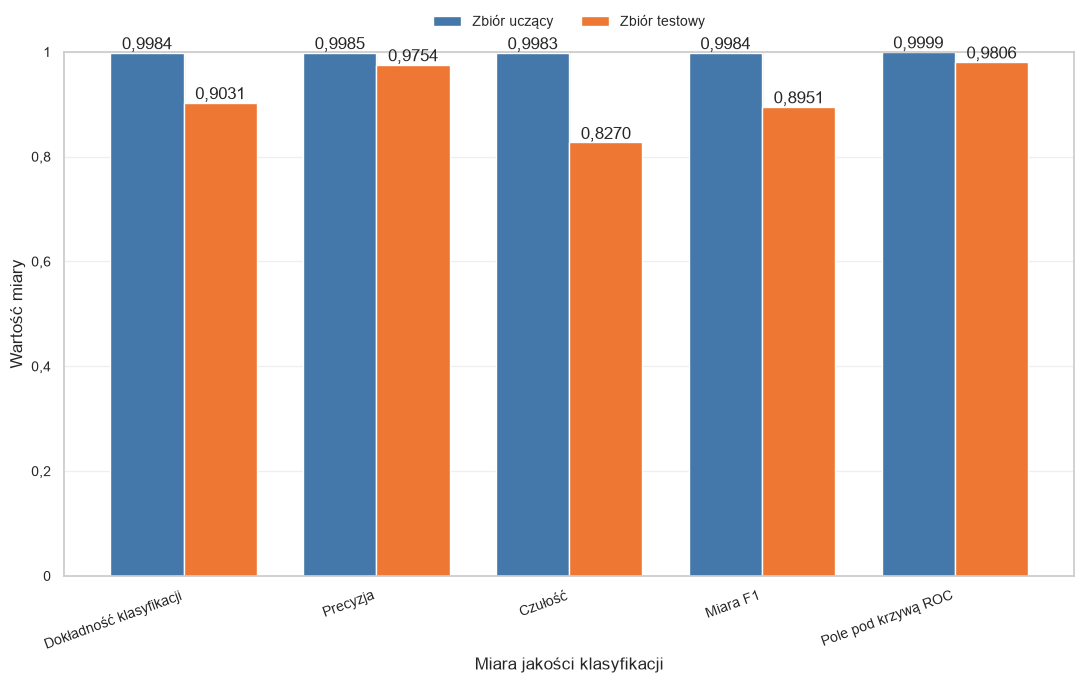

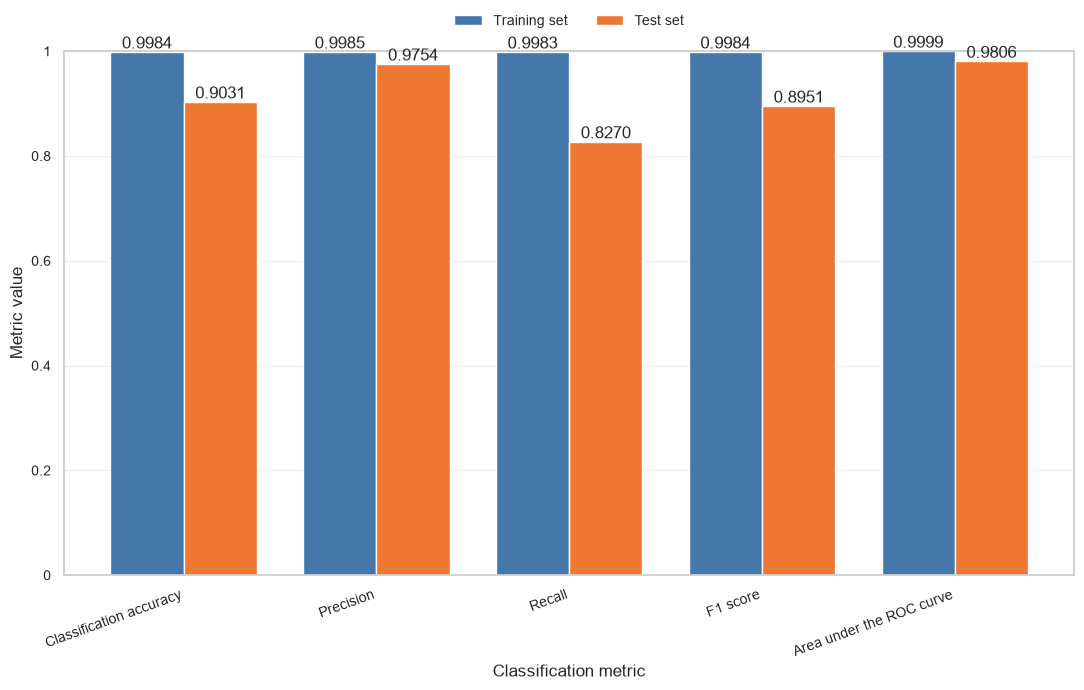

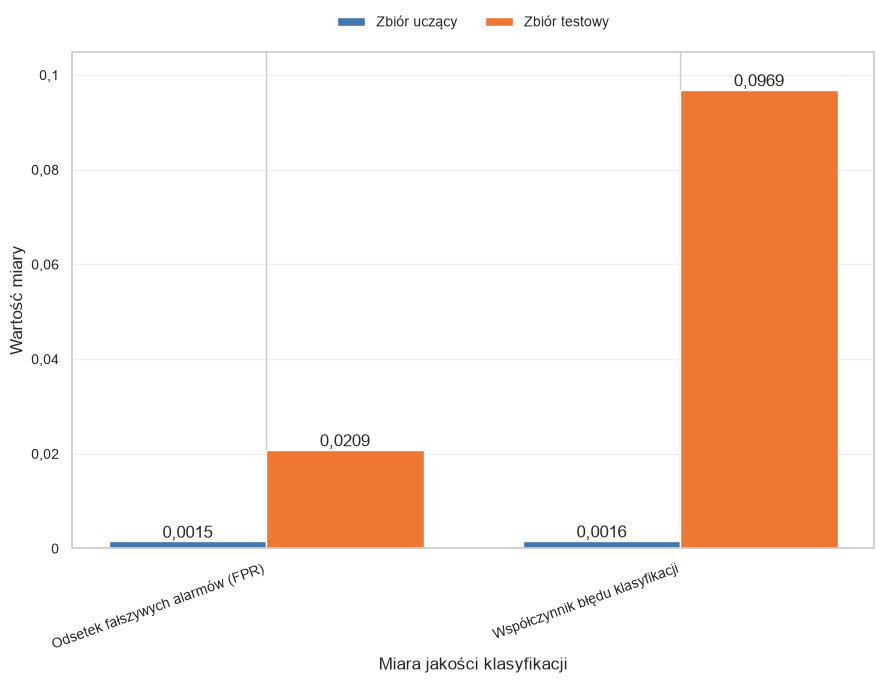

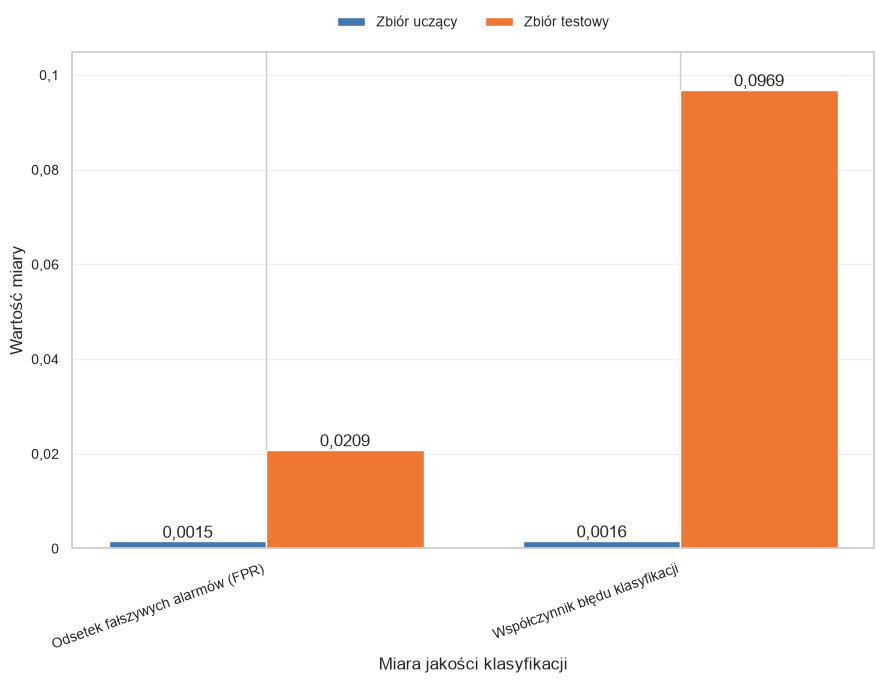

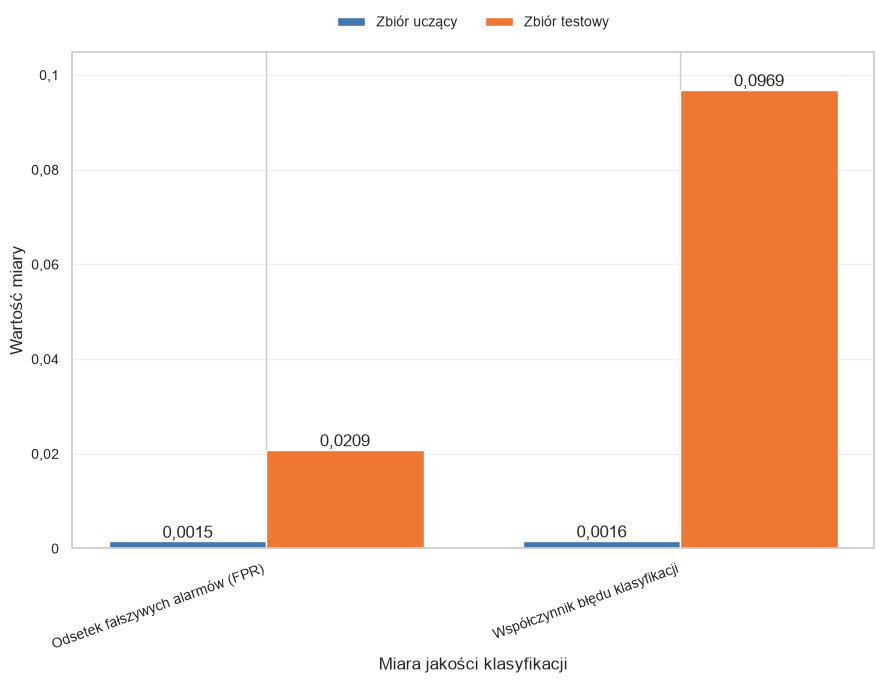

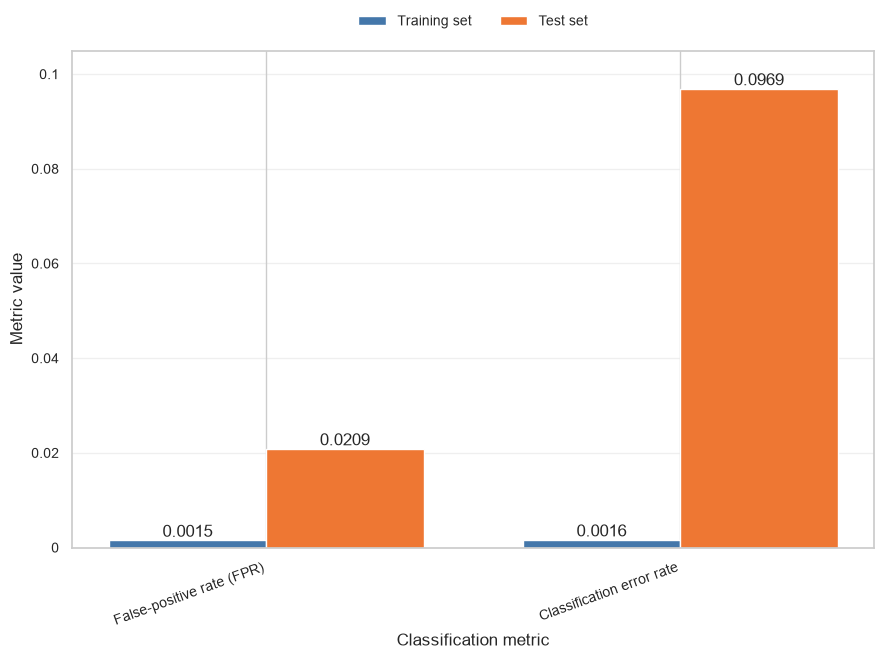


MACIERZ POMYŁEK:
  • Prawdziwie negatywne (TN): 10,281
  • Fałszywie pozytywne (FP): 219
  • Fałszywie negatywne (FN): 1,816
  • Prawdziwie pozytywne (TP): 8,684

PIĘCIOKROTNA WALIDACJA KRZYŻOWA:
  • Średni wynik ROC-AUC: 0.9944 ± 0.0003
  • Min: 0.9940
  • Max: 0.9947

PORÓWNANIE WYNIKÓW
Metryka                  Pełny zbiór Zoptymalizowany zbiór
--------------------------------------------------------------------------------
Accuracy                      0.9011          0.9031 (+0.0020)
Precision                     0.9741          0.9754 (+0.0013)
Recall                        0.8242          0.8270 (+0.0029)
False_positive_rate           0.0219          0.0209 (-0.0010)
F1                            0.8929          0.8951 (+0.0022)
Auc_roc                       0.9793          0.9806 (+0.0013)


In [8]:
evaluation_results = {}

for dataset_name, model_data in trained_models.items():
    print(f"\n{'='*80}")
    print(f"EWALUACJA MODELU - {dataset_name.upper()}")
    print(f"{'='*80}")

    model = model_data['model']
    data = train_test_data[dataset_name]

    X_test = data['X_test']
    y_test = data['y_test']
    X_train = data['X_train']
    y_train = data['y_train']

    y_val_proba = model.predict_proba(data['X_val'])[:, 1]
    threshold_info = calibrate_threshold(
        data['y_val'], y_val_proba,
        max_false_positive_rate=DEFAULT_MAX_FALSE_POSITIVE_RATE,
        min_recall=DEFAULT_MIN_RECALL,
    )
    decision_threshold = threshold_info['threshold']
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_pred_proba >= decision_threshold).astype(int)
    y_train_proba = model.predict_proba(X_train)[:, 1]
    y_train_pred = (y_train_proba >= decision_threshold).astype(int)

    cm = confusion_matrix(y_test, y_pred)
    tn, fp, fn, tp = cm.ravel()
    false_positive_rate = fp / (fp + tn) if (fp + tn) else 0.0

    train_cm = confusion_matrix(y_train, y_train_pred)
    train_tn, train_fp, train_fn, train_tp = train_cm.ravel()
    train_false_positive_rate = train_fp / (train_fp + train_tn) if (train_fp + train_tn) else 0.0
    train_accuracy = accuracy_score(y_train, y_train_pred)
    train_precision = precision_score(y_train, y_train_pred)
    train_recall = recall_score(y_train, y_train_pred)
    train_f1 = f1_score(y_train, y_train_pred)
    accuracy = accuracy_score(y_test, y_pred)
    train_error_rate = 1.0 - accuracy_score(y_train, y_train_pred)
    test_error_rate = 1.0 - accuracy
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_roc = roc_auc_score(y_test, y_pred_proba)
    train_auc_roc = roc_auc_score(y_train, y_train_proba)
    train_bce = log_loss(y_train, y_train_proba)
    test_bce = log_loss(y_test, y_pred_proba)

    cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring='roc_auc')

    evaluation_results[dataset_name] = {
        'y_pred': y_pred,
        'y_pred_proba': y_pred_proba,
        'confusion_matrix': cm,
        'train_accuracy': train_accuracy,
        'train_precision': train_precision,
        'train_recall': train_recall,
        'train_false_positive_rate': train_false_positive_rate,
        'train_f1': train_f1,
        'accuracy': accuracy,
        'train_error_rate': train_error_rate,
        'test_error_rate': test_error_rate,
        'precision': precision,
        'recall': recall,
        'false_positive_rate': false_positive_rate,
        'decision_threshold': decision_threshold,
        'threshold_calibration': threshold_info,
        'f1': f1,
        'auc_roc': auc_roc,
        'train_auc_roc': train_auc_roc,
        'train_bce': train_bce,
        'test_bce': test_bce,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std()
    }

    print(f"\nWYNIKI NA ZBIORZE TESTOWYM:")
    print(f"  • Dokładność (Accuracy): {accuracy:.4f}")
    print(f"  • Precyzja: {precision:.4f}")
    print(f"  • Czułość: {recall:.4f}")
    print(f"  • Współczynnik fałszywie dodatnich (FPR): {false_positive_rate:.4f} ({false_positive_rate:.2%})")
    print(f"  • Próg skalibrowany na walidacji: {decision_threshold:.4f}")
    print(f"  • Walidacyjny FPR przy wybranym progu: {threshold_info['validation_fpr']:.2%}")
    print(f"  • Walidacyjna czułość przy wybranym progu: {threshold_info['validation_recall']:.2%}")
    print(f"  • Docelowy FPR kalibracji: {threshold_info['target_fpr']:.2%}")
    print(f"  • Miara F1 (F1-Score): {f1:.4f}")
    print(f"  • AUC-ROC: {auc_roc:.4f}")
    print(f"  • Błąd uczenia: {train_error_rate:.4f}")
    print(f"  • Błąd testowania: {test_error_rate:.4f}")

    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'random_forest_final_error_rate.png'
    )

    train_metrics, test_metrics = classification_metric_sets(
        evaluation_results[dataset_name]
    )
    metric_figures = plot_final_train_test_metric_groups(
        train_metrics, test_metrics
    )
    for group_name, metric_figure in metric_figures.items():
        save_dataset_figure(
            metric_figure, PLOTS_DIR, dataset_name,
            f'random_forest_metrics_{group_name}.png',
        )
        plt.show()

    print(f"\nMACIERZ POMYŁEK:")
    print(f"  • Prawdziwie negatywne (TN): {tn:,}")
    print(f"  • Fałszywie pozytywne (FP): {fp:,}")
    print(f"  • Fałszywie negatywne (FN): {fn:,}")
    print(f"  • Prawdziwie pozytywne (TP): {tp:,}")

    print(f"\nPIĘCIOKROTNA WALIDACJA KRZYŻOWA:")
    print(f"  • Średni wynik ROC-AUC: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
    print(f"  • Min: {cv_scores.min():.4f}")
    print(f"  • Max: {cv_scores.max():.4f}")

print(f"\n{'='*80}")
print("PORÓWNANIE WYNIKÓW")
print(f"{'='*80}")
print(f"{'Metryka':<20} {'Pełny zbiór':>15} {'Zoptymalizowany zbiór':>20}")
print(f"{'-'*80}")
for metric in ['accuracy', 'precision', 'recall', 'false_positive_rate', 'f1', 'auc_roc']:
    full_val = evaluation_results['Pełny zbiór'][metric]
    opt_val = evaluation_results['Zoptymalizowany zbiór'][metric]
    diff = opt_val - full_val
    diff_str = f"({diff:+.4f})" if diff != 0 else ""
    print(f"{metric.capitalize():<20} {full_val:>15.4f} {opt_val:>15.4f} {diff_str:>5}")

## 7. Wizualizacja kompleksowa i krzywa uczenia


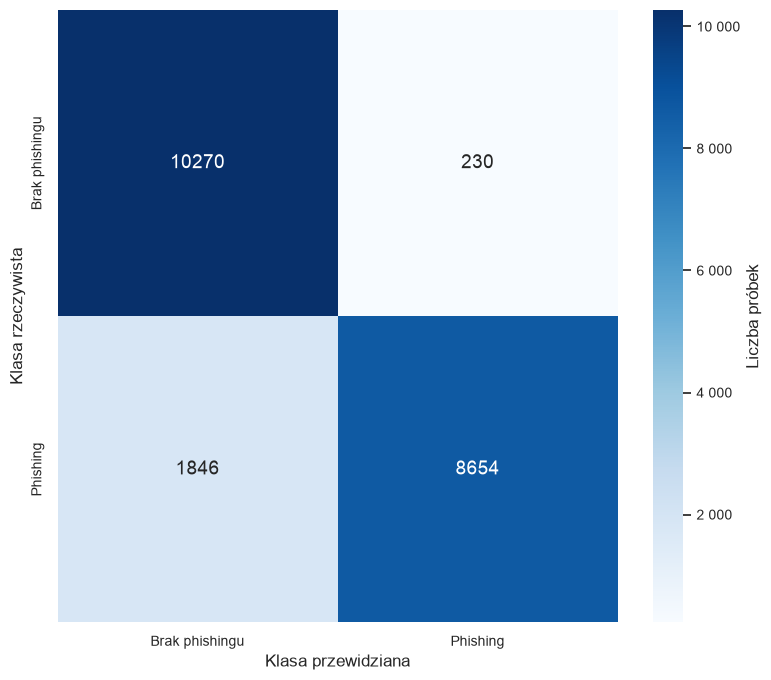

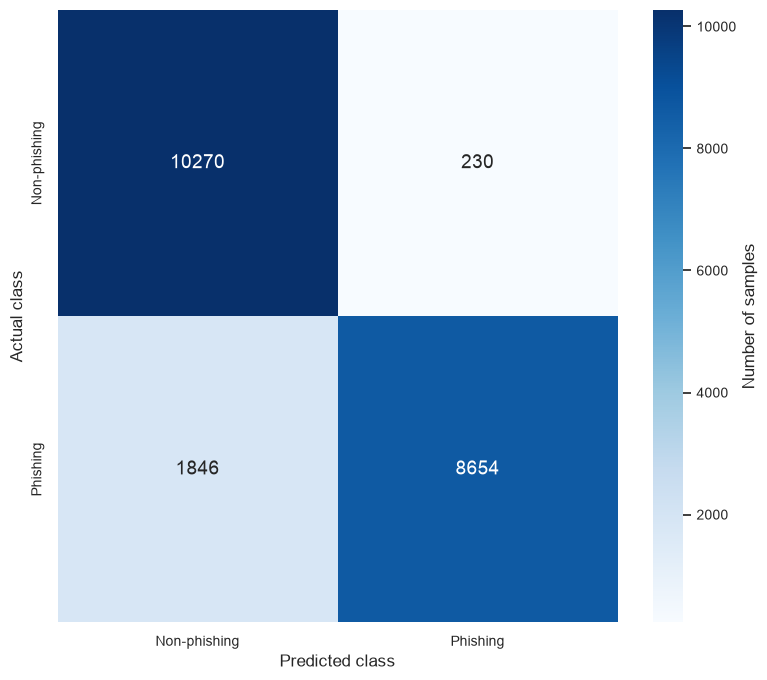

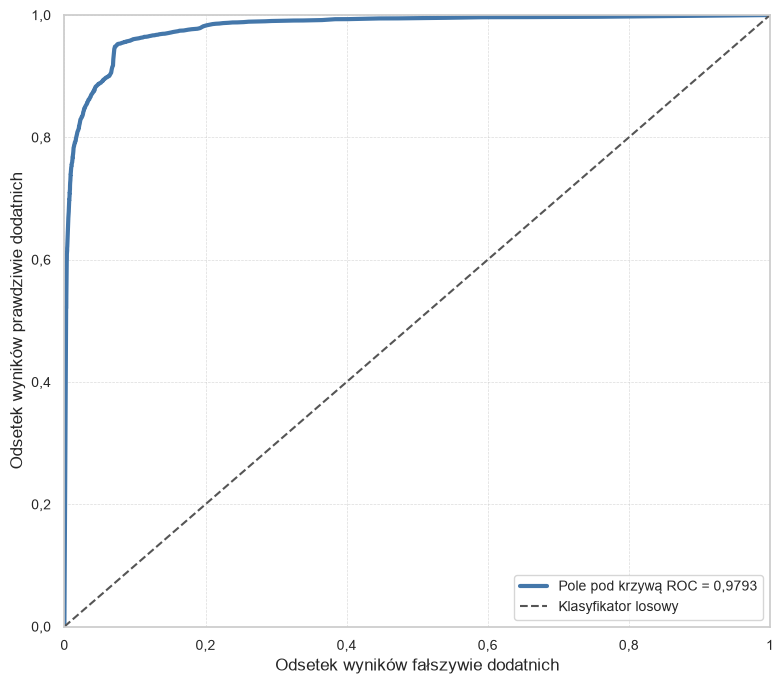

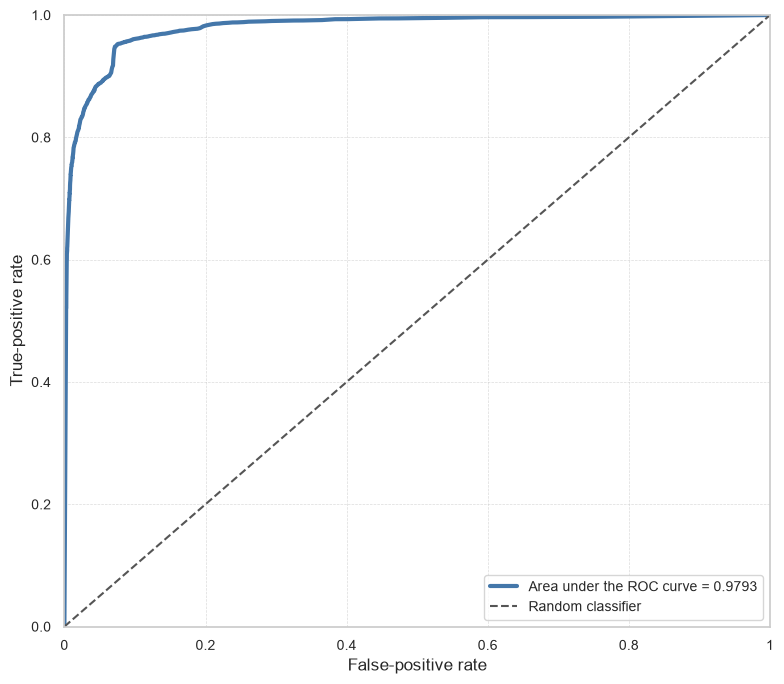

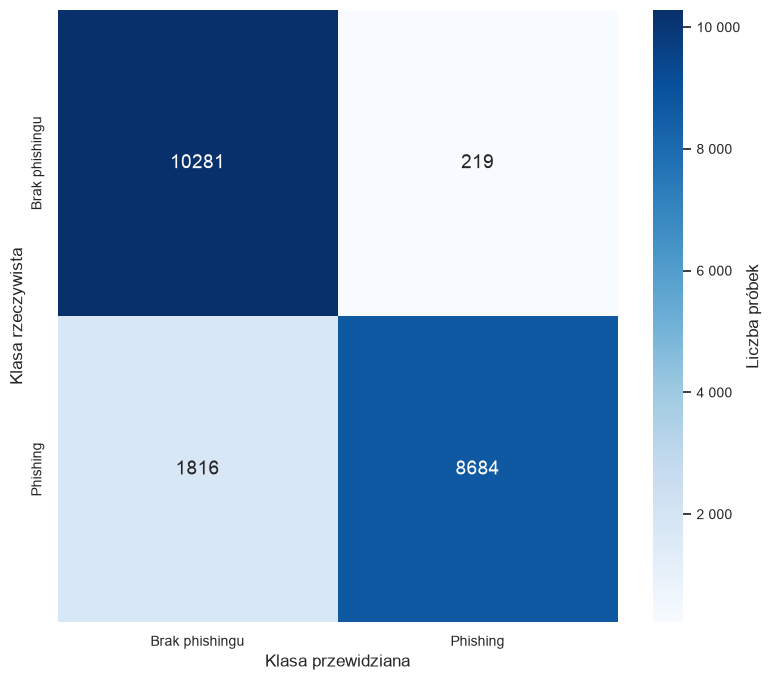

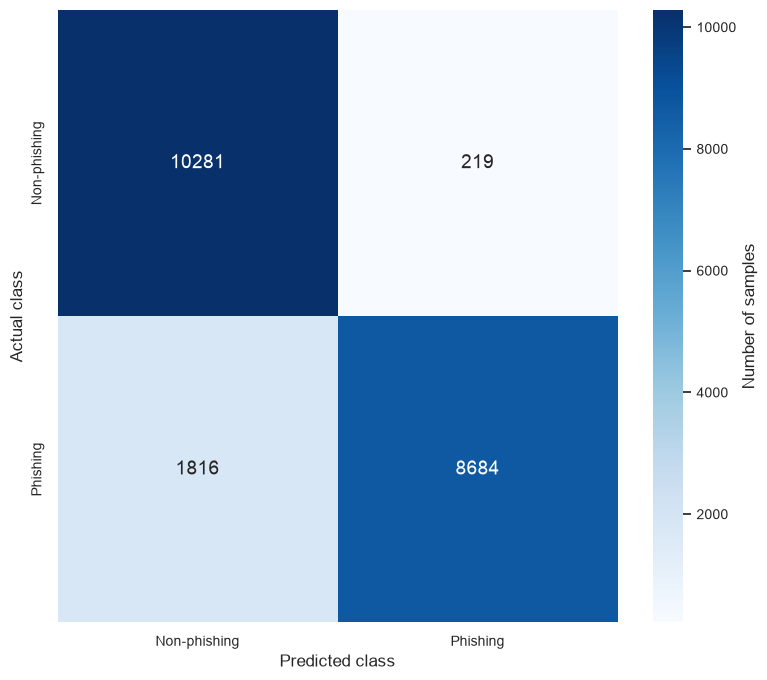

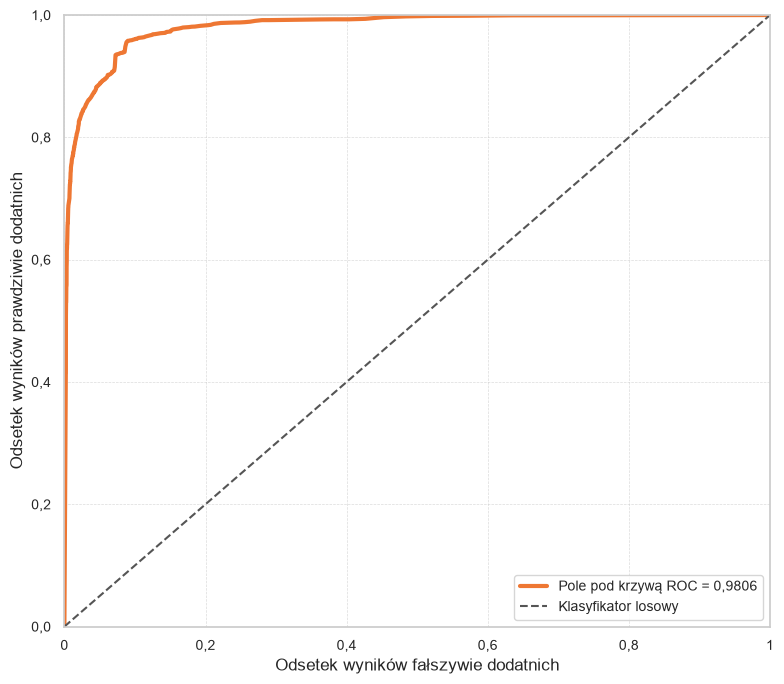

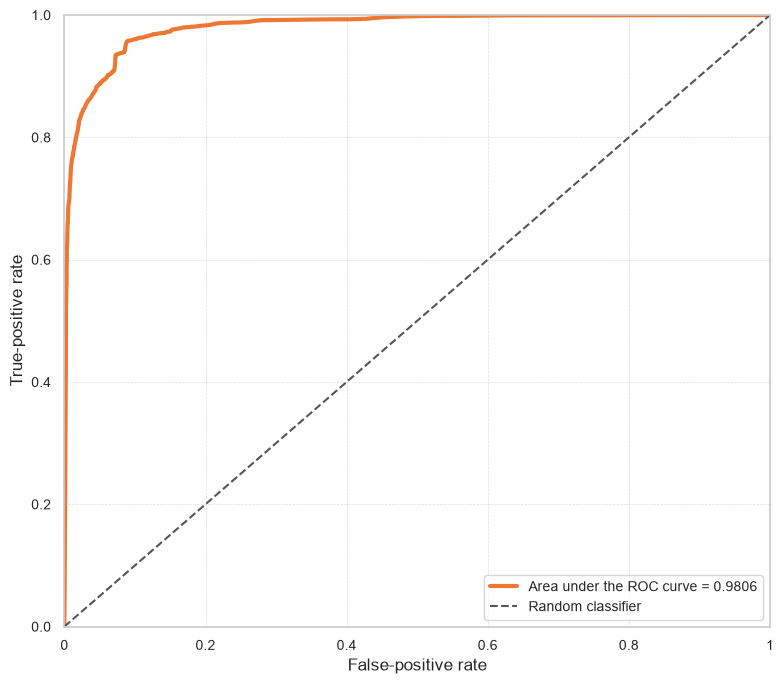

In [9]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    evaluation = evaluation_results[dataset_name]

    confusion_figure, _ = plot_confusion_matrix(
        evaluation['confusion_matrix'], dataset_name,
    )
    save_dataset_figure(
        confusion_figure, PLOTS_DIR, dataset_name, 'random_forest_confusion_matrix.png'
    )
    plt.show()

    roc_figure, _ = plot_roc_curve(
        train_test_data[dataset_name]['y_test'], evaluation['y_pred_proba'], evaluation['auc_roc'], dataset_name,
    )
    save_dataset_figure(
        roc_figure, PLOTS_DIR, dataset_name, 'random_forest_roc_curve.png'
    )
    plt.show()


## 7.1. Porównanie metryk w postaci wykresów słupkowych


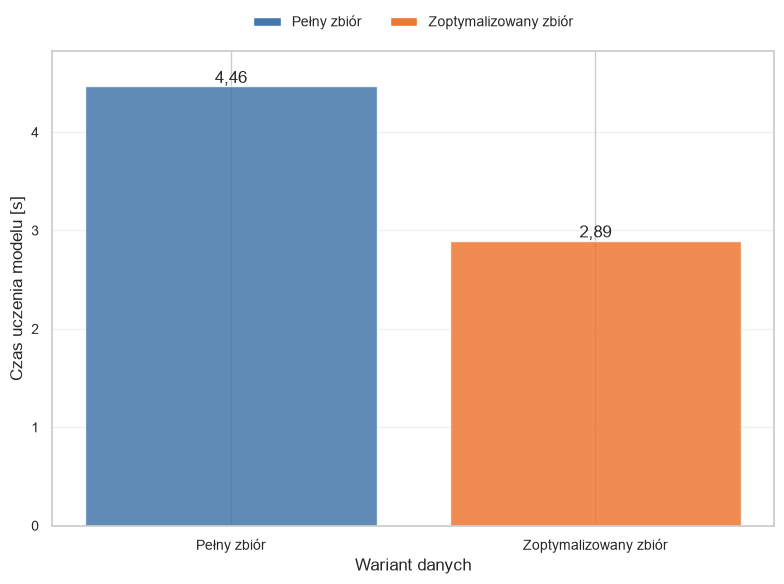

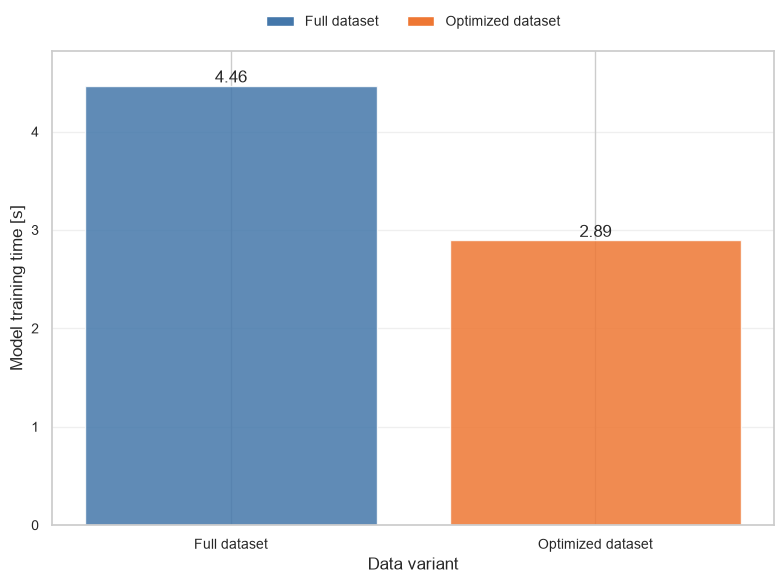

,Wariant danych,Liczba cech,Redukcja liczby cech,Redukcja [%]
0,Pełny zbiór,110,0,0.00
1,Zoptymalizowany zbiór,47,63,57.27


In [10]:
training_times = {}
feature_counts = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    training_times[dataset_name] = float(trained_models[dataset_name]['training_time'])
    feature_counts[dataset_name] = int(data_splits[dataset_name]['feature_count'])
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'random_forest_training_time.png'
    )
    remove_dataset_figure(
        PLOTS_DIR, dataset_name, 'random_forest_feature_count.png'
    )

time_figure, _ = plot_training_time_comparison(training_times)
save_comparison_figure(
    time_figure, PLOTS_DIR / 'random_forest_training_time_comparison.png'
)
plt.show()

feature_count_rows = feature_count_comparison_rows(
    feature_counts['Pełny zbiór'],
    feature_counts['Zoptymalizowany zbiór'],
)
display(pd.DataFrame(feature_count_rows))


## 7.1a. Wizualizacja przykładowego drzewa decyzyjnego z lasu


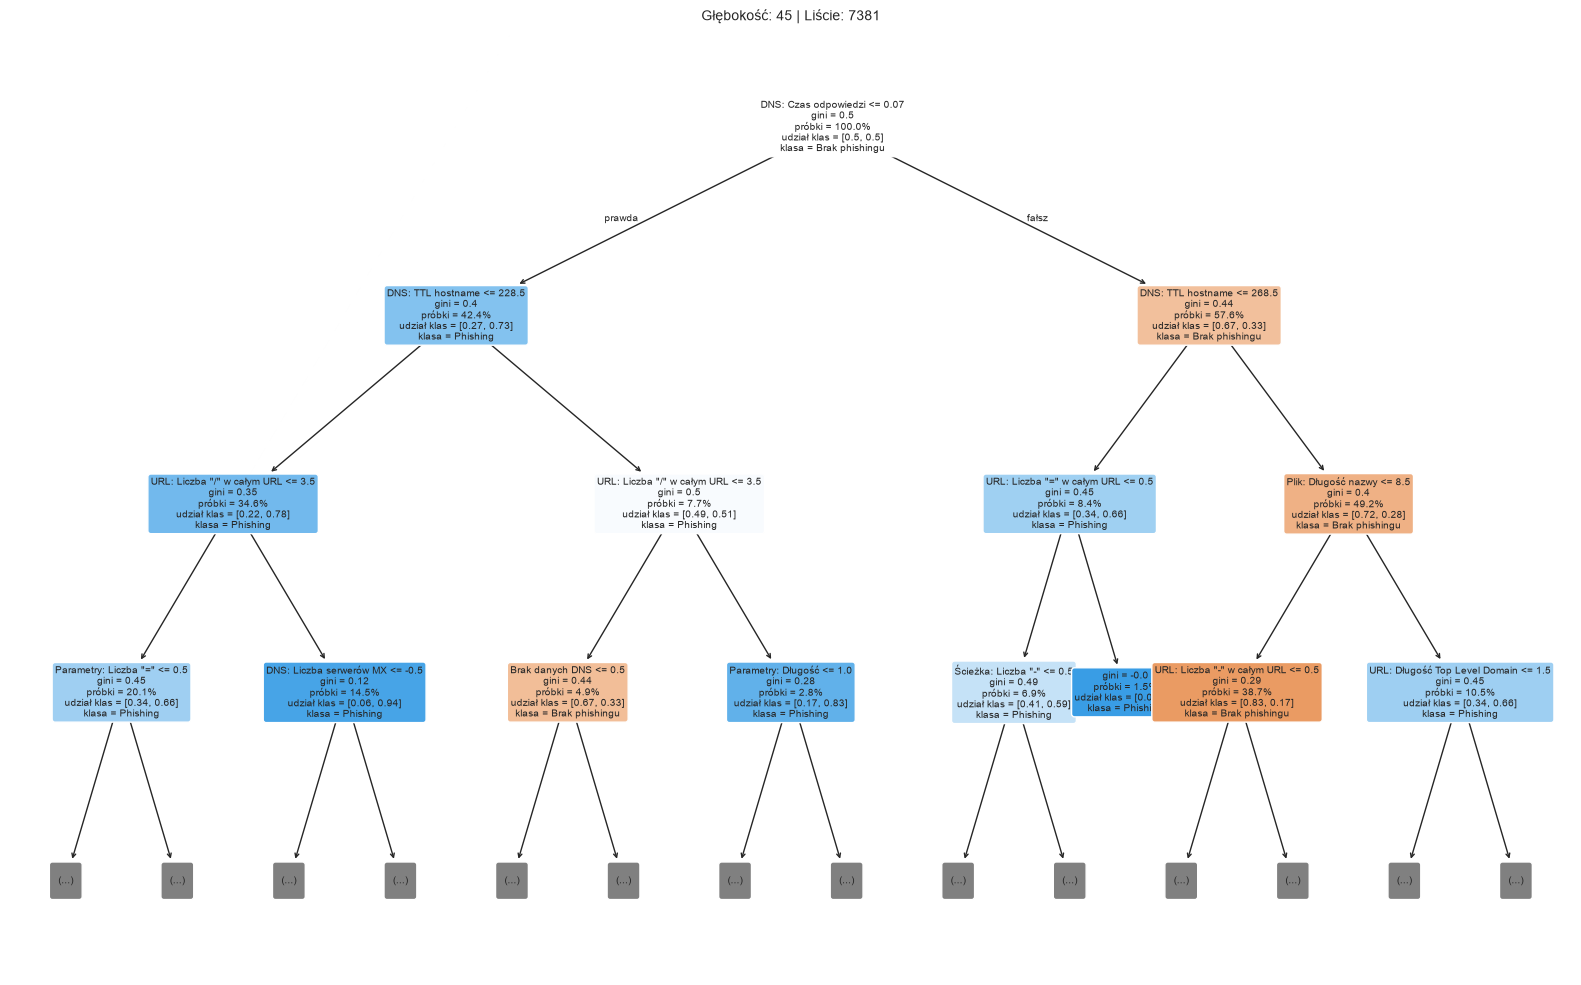

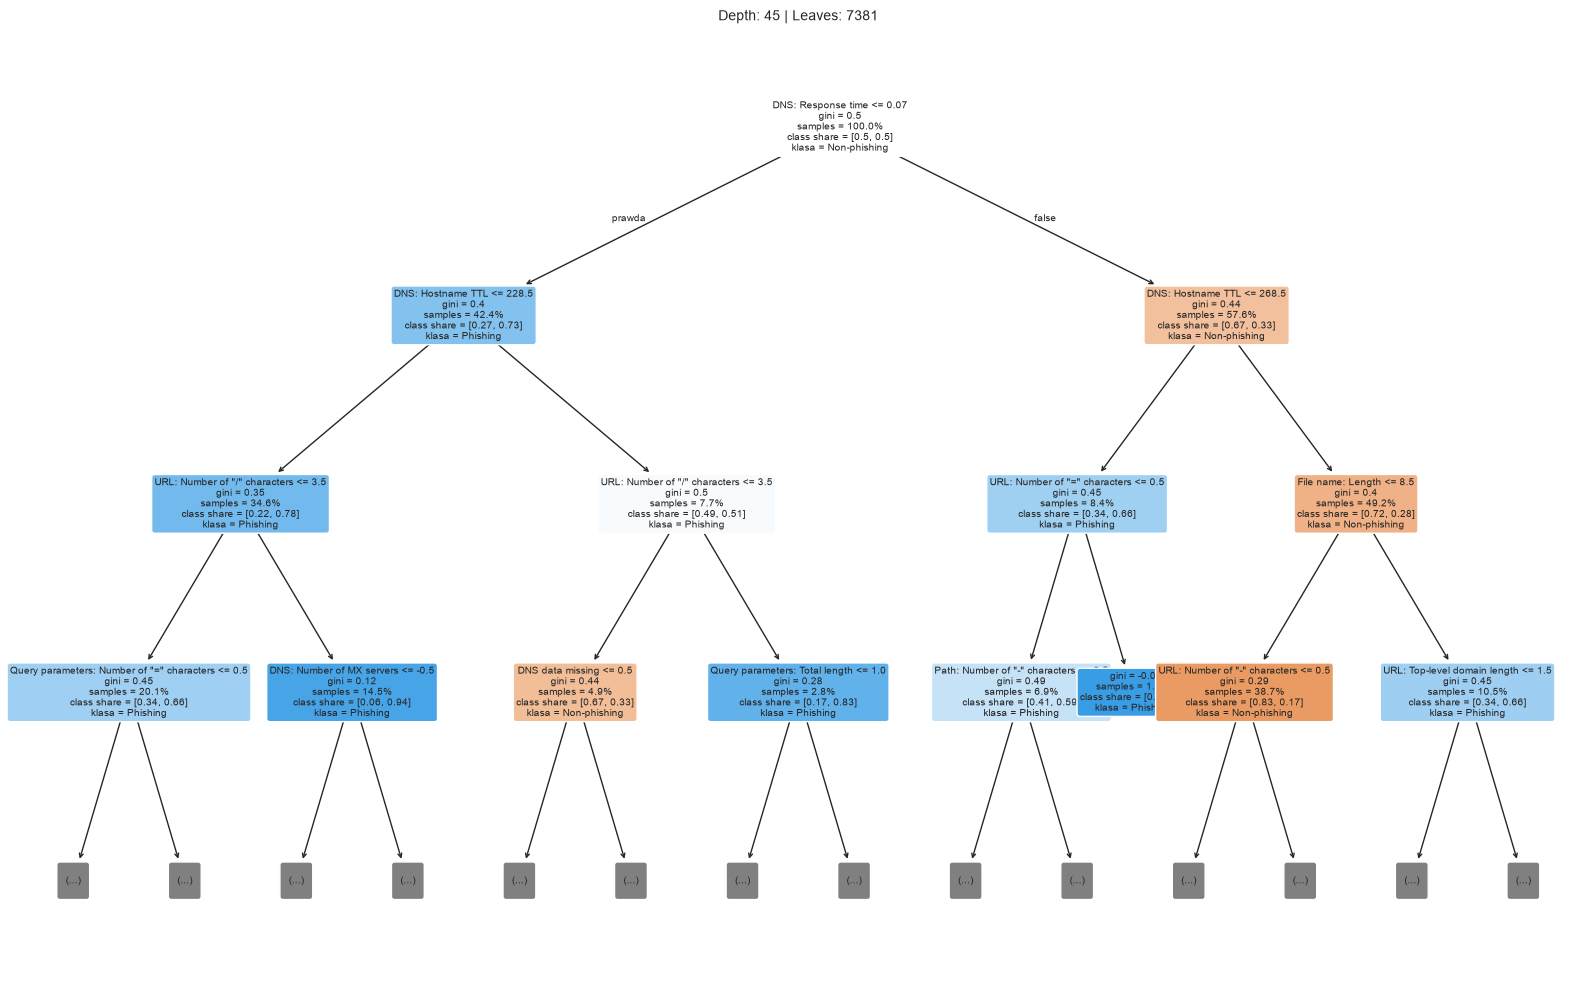

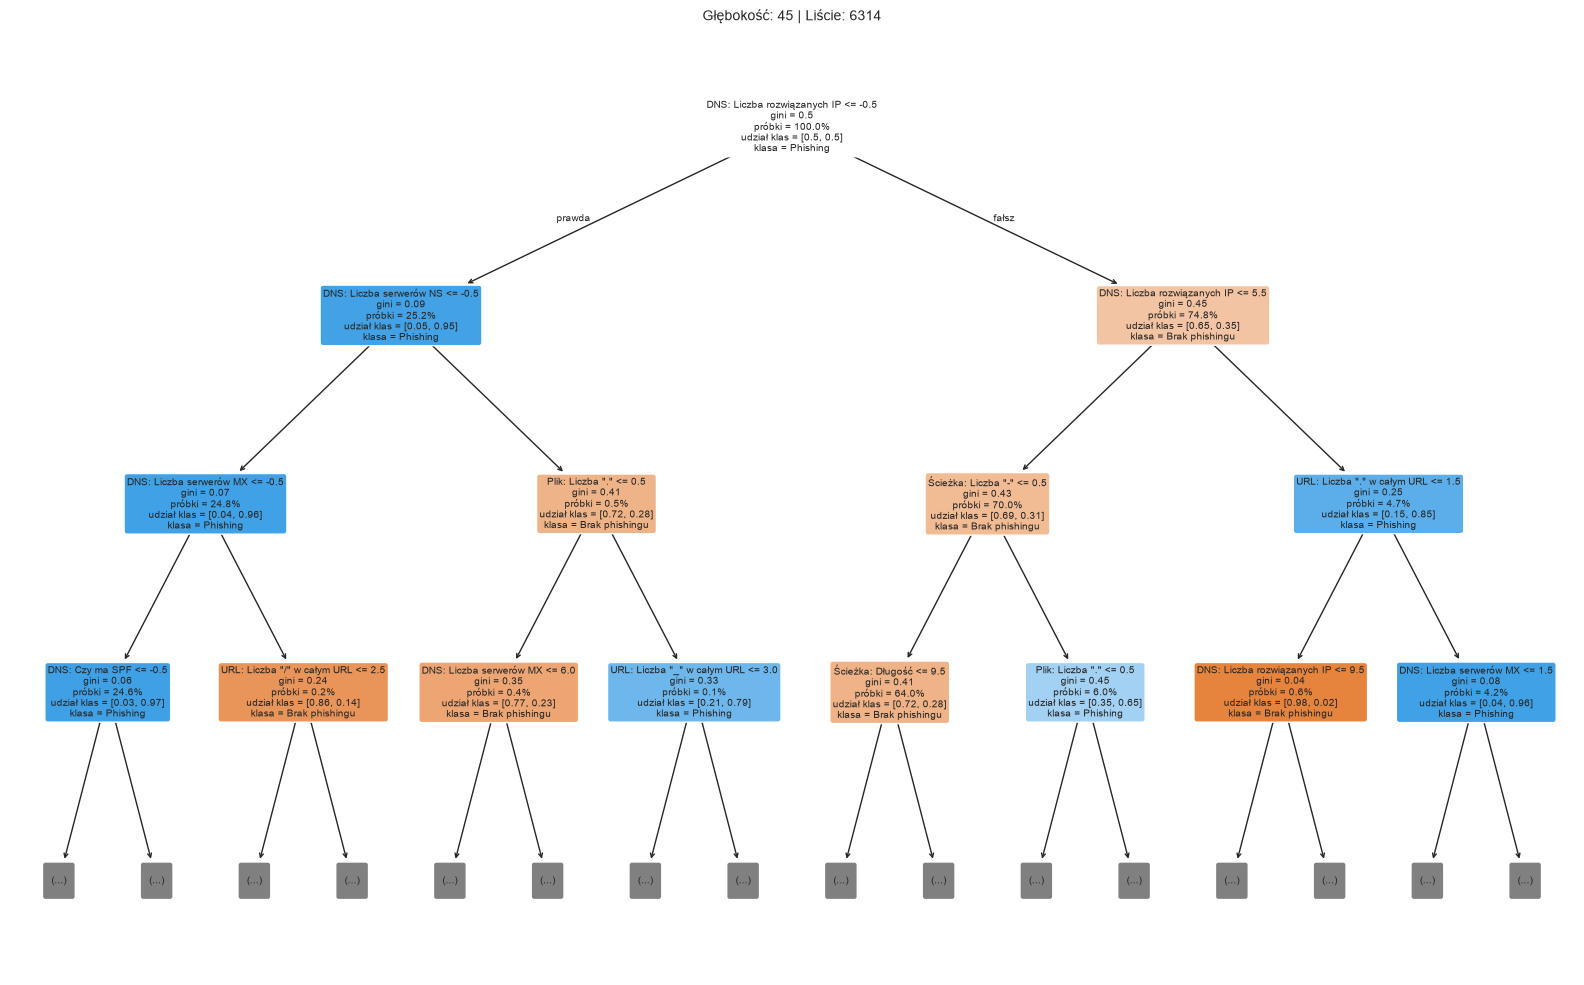

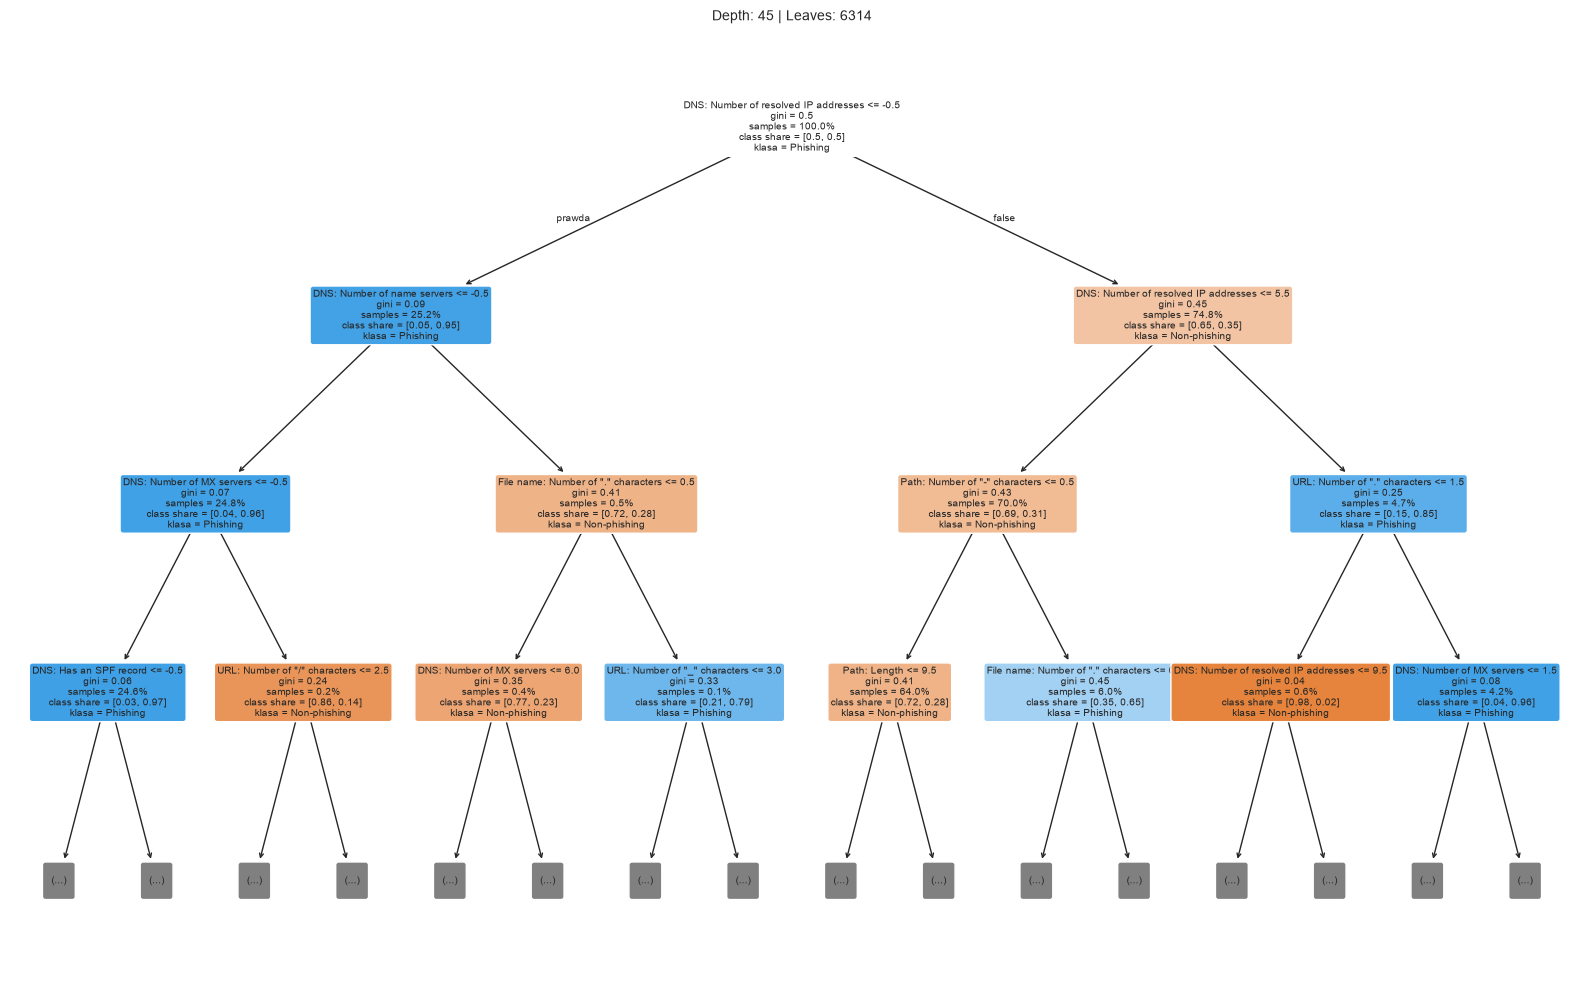

STATYSTYKI DRZEW W LESIE
Pełny zbiór: drzewa=300, średnia głębokość=47.30, średnia liczba liści=7417.96
Zoptymalizowany zbiór: drzewa=300, średnia głębokość=43.47, średnia liczba liści=6274.79


In [11]:
dataset_names = list(trained_models.keys())
for dataset_name in dataset_names:
    model = trained_models[dataset_name]['model']
    X_train = train_test_data[dataset_name]['X_train']
    tree = model.estimators_[0]
    feature_names_readable = [get_readable_name(column) for column in X_train.columns]
    figure, axis = plt.subplots(figsize=(16, 10))
    plot_tree(
        tree, feature_names=feature_names_readable,
        class_names=['Legalny URL', 'Phishing'], filled=True, rounded=True,
        fontsize=7, max_depth=3, ax=axis, proportion=True, precision=2,
        impurity=True,
    )
    for node_label in axis.texts:
        translated = node_label.get_text()
        translated = translated.replace('samples', 'próbki')
        translated = translated.replace('value', 'udział klas')
        translated = translated.replace('class', 'klasa')
        translated = translated.replace('True', 'prawda')
        translated = translated.replace('False', 'fałsz')
        node_label.set_text(translated)
    axis.text(
        0.5, 1.01,
        f'Głębokość: {tree.get_depth()} | Liście: {tree.get_n_leaves()}',
        transform=axis.transAxes, ha='center', va='bottom', fontsize=10,
    )
    figure.tight_layout()
    save_dataset_figure(
        figure, PLOTS_DIR, dataset_name, 'random_forest_tree_visualization.png'
    )
    plt.show()

print("STATYSTYKI DRZEW W LESIE")
for dataset_name in dataset_names:
    model = trained_models[dataset_name]['model']
    tree_depths = [tree.get_depth() for tree in model.estimators_]
    tree_leaves = [tree.get_n_leaves() for tree in model.estimators_]
    print(f"{dataset_name}: drzewa={len(model.estimators_)}, "
          f"średnia głębokość={np.mean(tree_depths):.2f}, "
          f"średnia liczba liści={np.mean(tree_leaves):.2f}")


## 7.1b. Ścieżka decyzyjna dla przykładowego URL


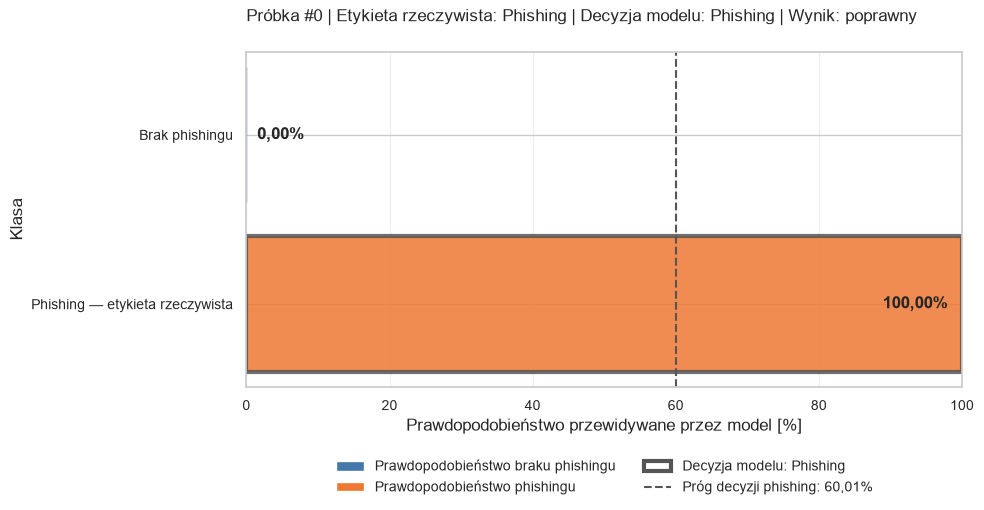

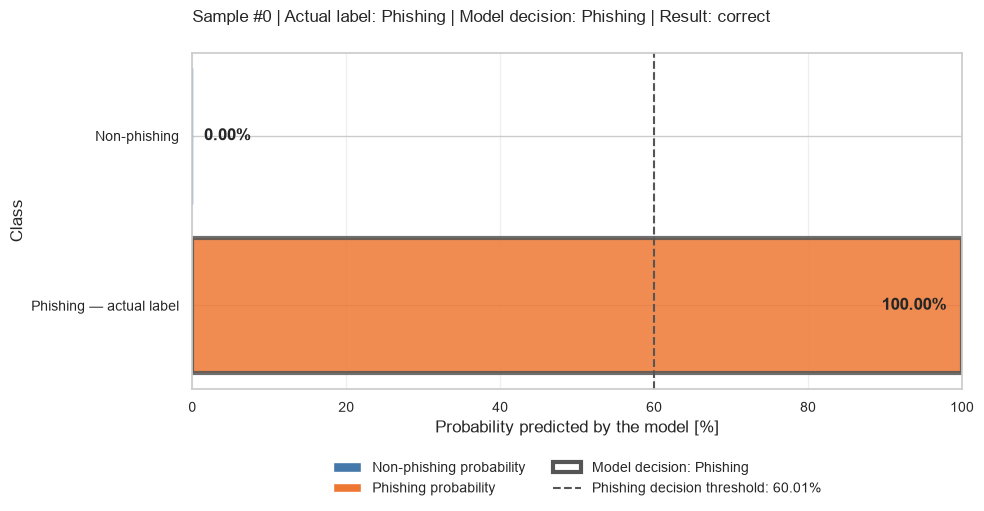

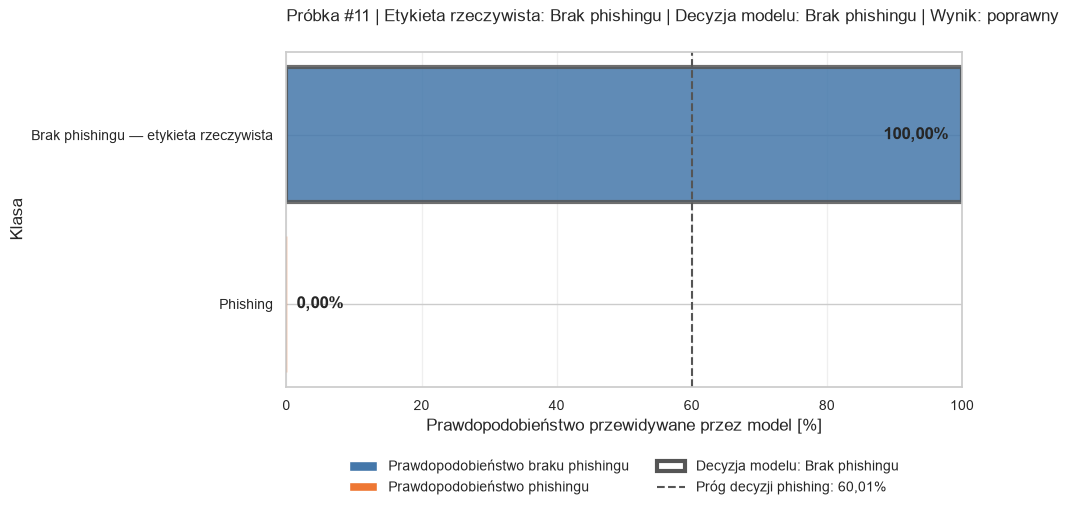

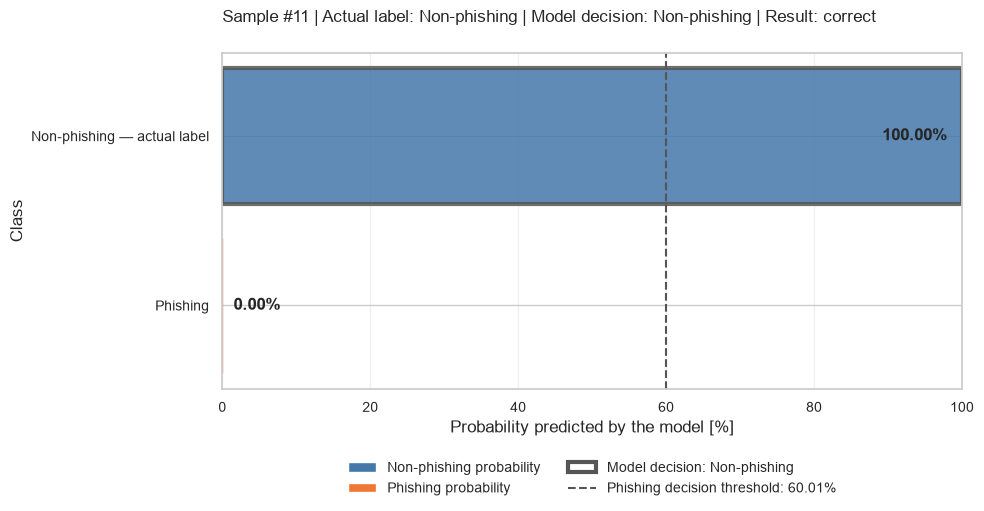

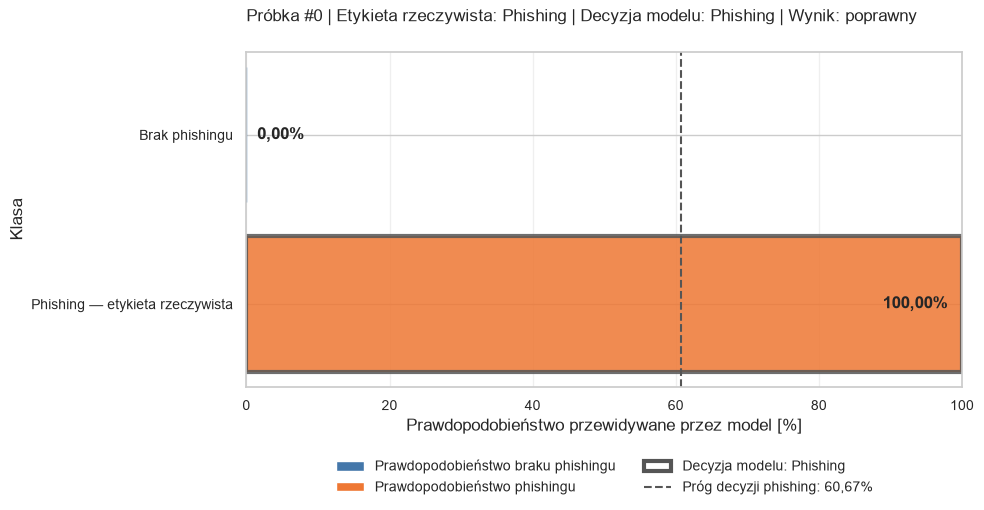

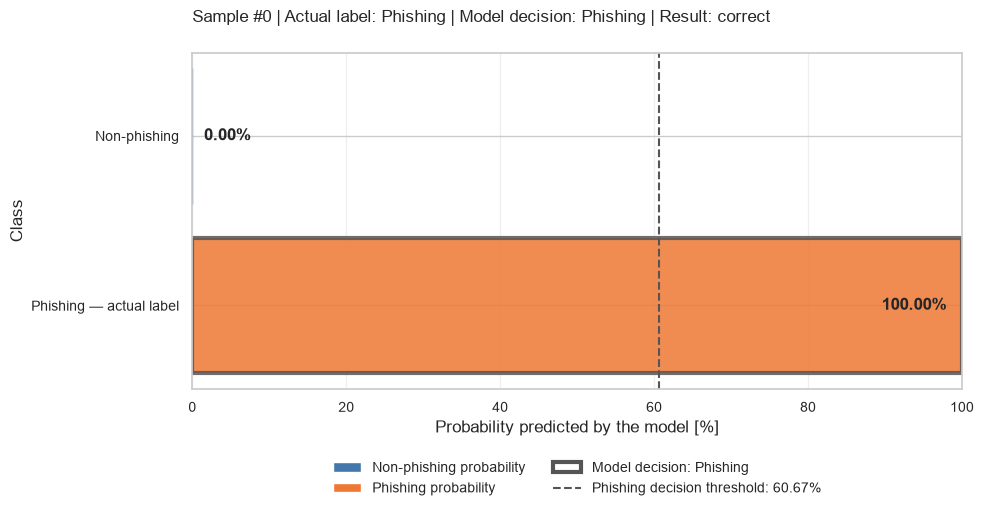

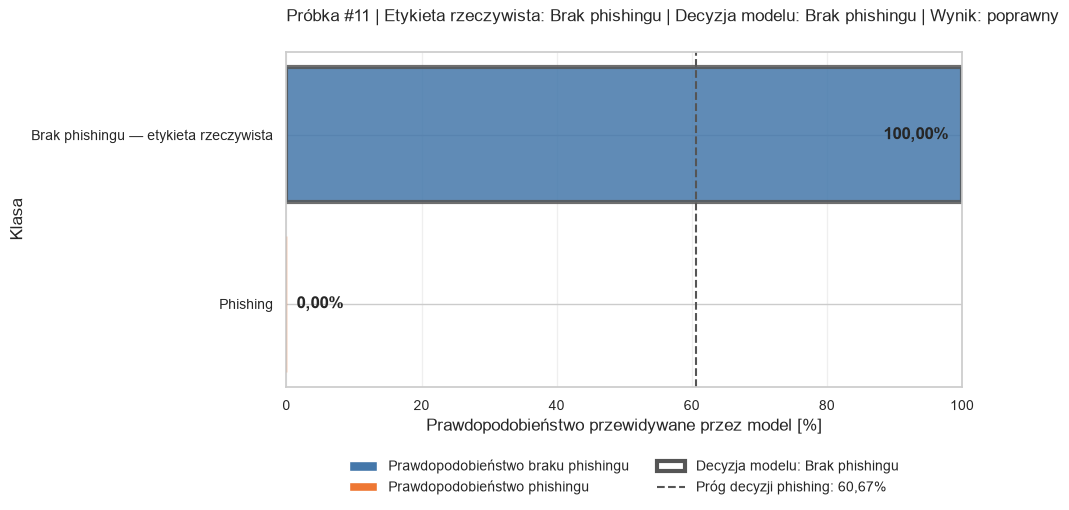

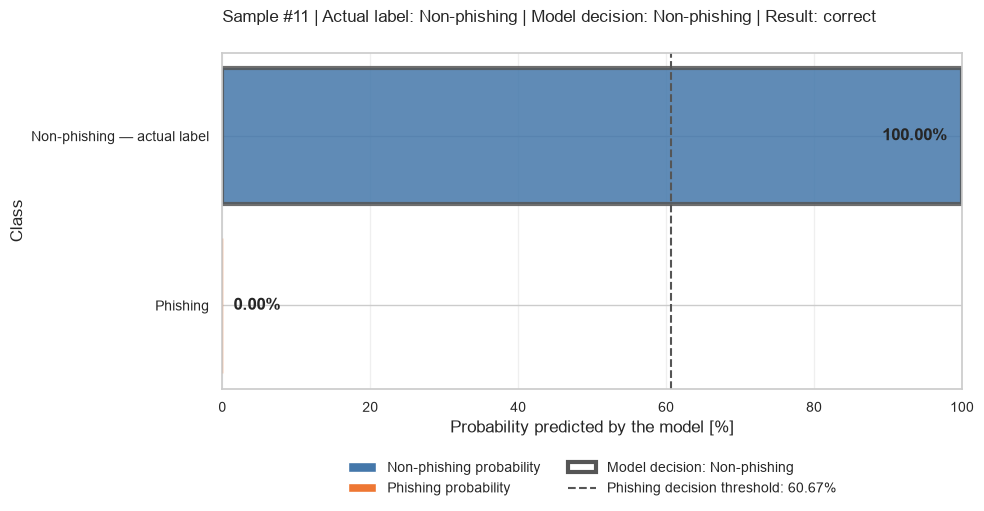

In [12]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    true_labels = train_test_data[dataset_name]['y_test']
    label_values = np.asarray(true_labels, dtype=int)
    probabilities = np.asarray(
        evaluation_results[dataset_name]['y_pred_proba'], dtype=float
    ).reshape(-1)
    threshold = evaluation_results[dataset_name].get('decision_threshold', 0.5)
    sample_positions = {
        'phishing': int(np.flatnonzero(label_values == 1)[0]),
        'bez_phishingu': int(np.flatnonzero(label_values == 0)[0]),
    }
    for sample_kind, position in sample_positions.items():
        sample_id = (
            true_labels.index[position]
            if hasattr(true_labels, 'index') else position
        )
        for language in ['pl', 'en']:
            language_folder = 'pl' if language == 'pl' else 'eng'
            figure, _ = plot_sample_probability_prediction(
                probabilities[position], label_values[position], sample_id,
                decision_threshold=threshold, language=language,
            )
            save_dataset_figure(
                figure, PLOTS_DIR, dataset_name,
                f'{language_folder}/random_forest_sample_prediction_{sample_kind}.png',
            )
            plt.show()
    for obsolete_name in [
        'random_forest_voting_example_phishing.png',
        'random_forest_voting_example_bez_phishingu.png',
        'random_forest_voting_examples.png',
        'random_forest_probability_distribution.png',
        'random_forest_sample_prediction_phishing.png',
        'random_forest_sample_prediction_bez_phishingu.png',
        'random_forest_sample_prediction_phishing_pl.png',
        'random_forest_sample_prediction_phishing_en.png',
        'random_forest_sample_prediction_bez_phishingu_pl.png',
        'random_forest_sample_prediction_bez_phishingu_en.png',
    ]:
        remove_dataset_figure(PLOTS_DIR, dataset_name, obsolete_name)


## 7.2. Krzywe uczenia w pięciokrotnej walidacji krzyżowej

Oś pozioma przedstawia dziesięć rosnących rozmiarów podzbioru uczącego: od
10% do 100% danych dostępnych do uczenia w danym podziale. Dla każdego rozmiaru
model jest dopasowywany w pięciu podziałach. Każdy punkt linii uczenia jest
średnią miary obliczonej na pięciu podzbiorach uczących, a każdy punkt linii
walidacji jest średnią miary obliczonej na pięciu odpowiadających im
podzbiorach walidacyjnych. Pasmo oznacza ± jedno odchylenie standardowe.
Oś pozioma nie przedstawia liczby próbek walidacyjnych ani testowych.

Walidacja służy do oceny uogólniania modelu podczas jego opracowywania.
Nie jest testem końcowym. Niezależny zbiór testowy nie uczestniczy w
wyznaczaniu tych krzywych; porównanie końcowych wyników uczenia i testowania
znajduje się w sekcji ewaluacji modelu.


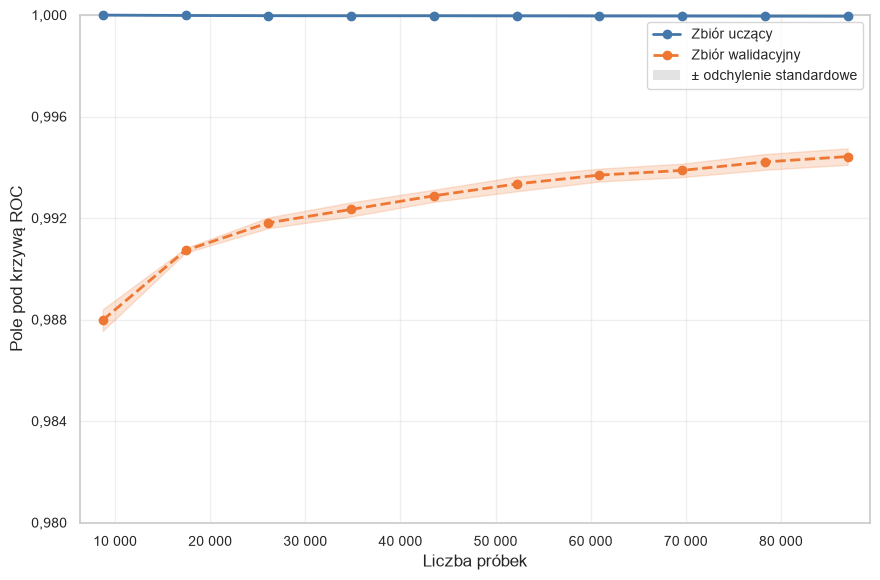

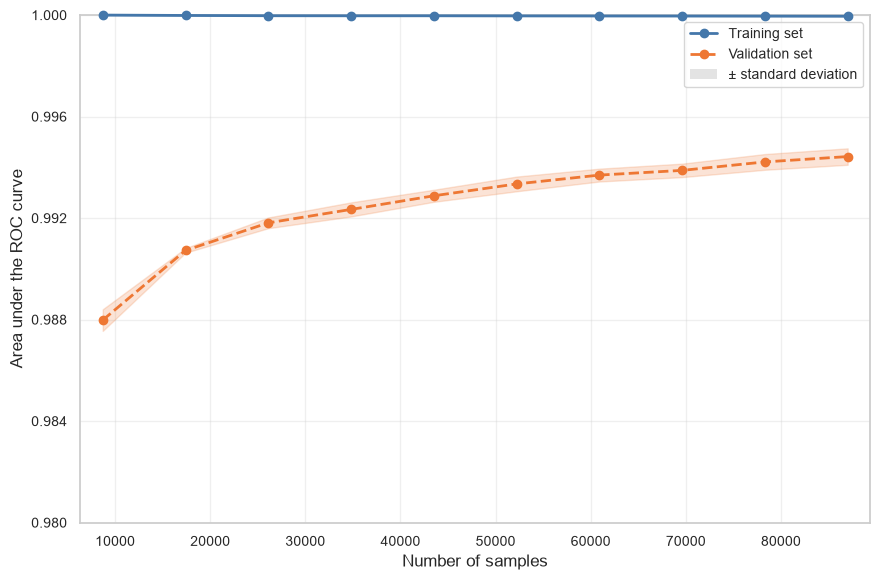

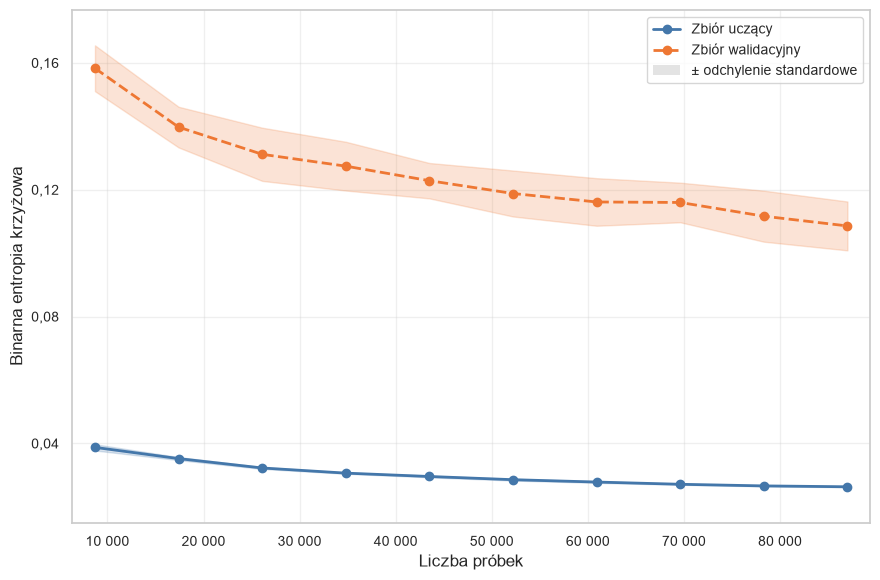

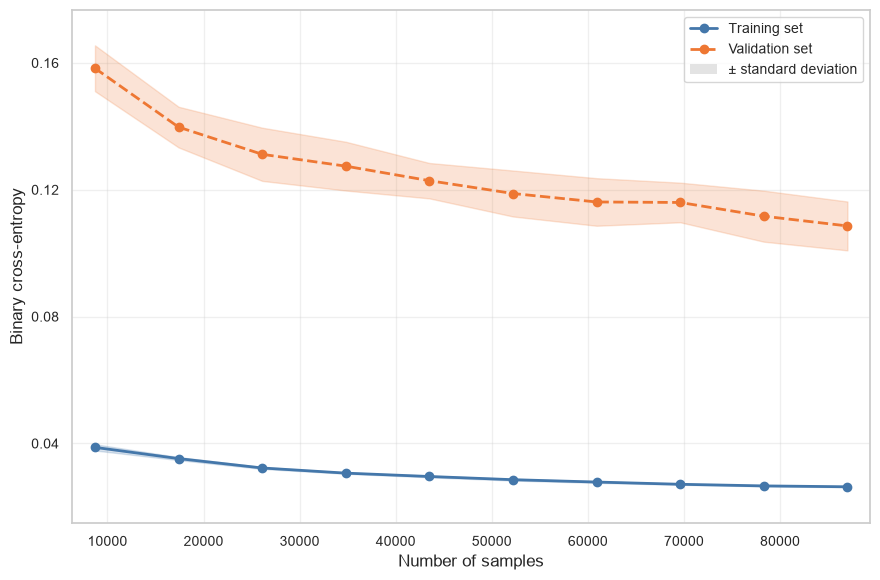

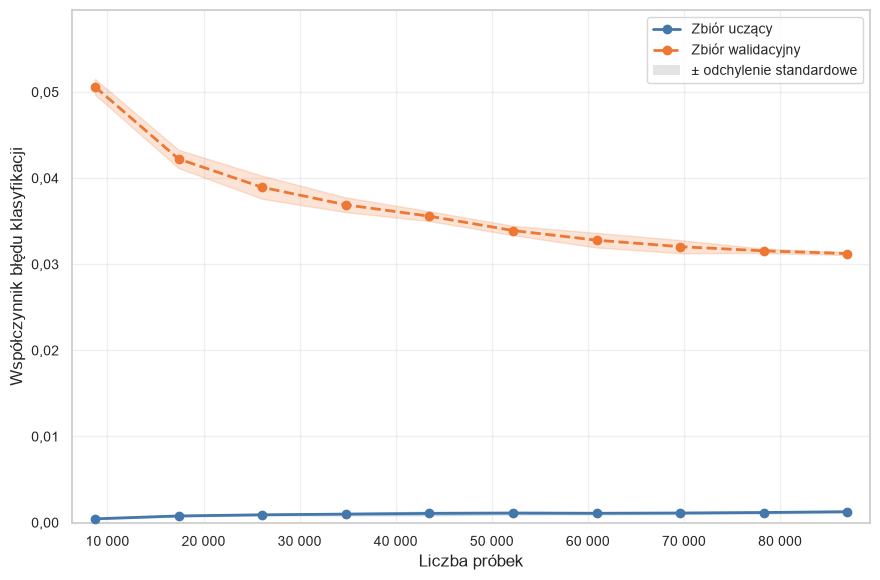

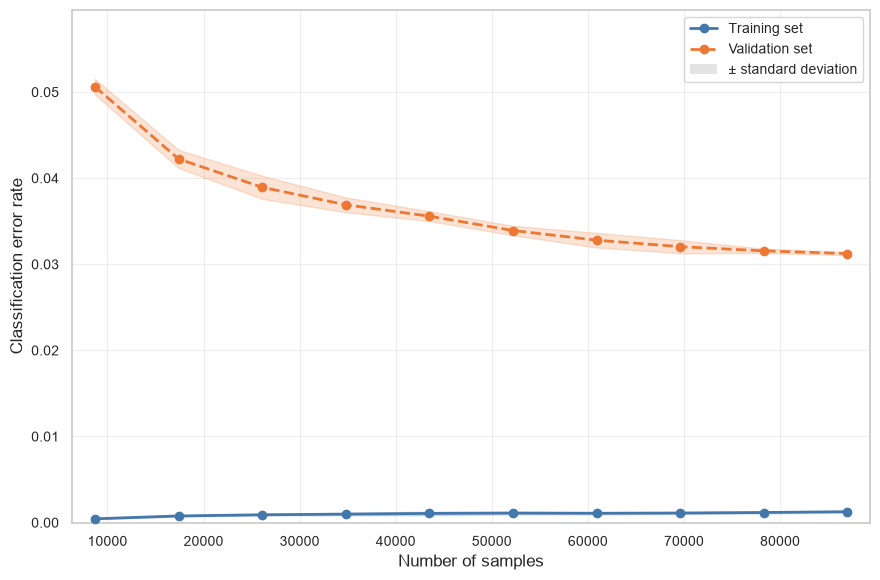

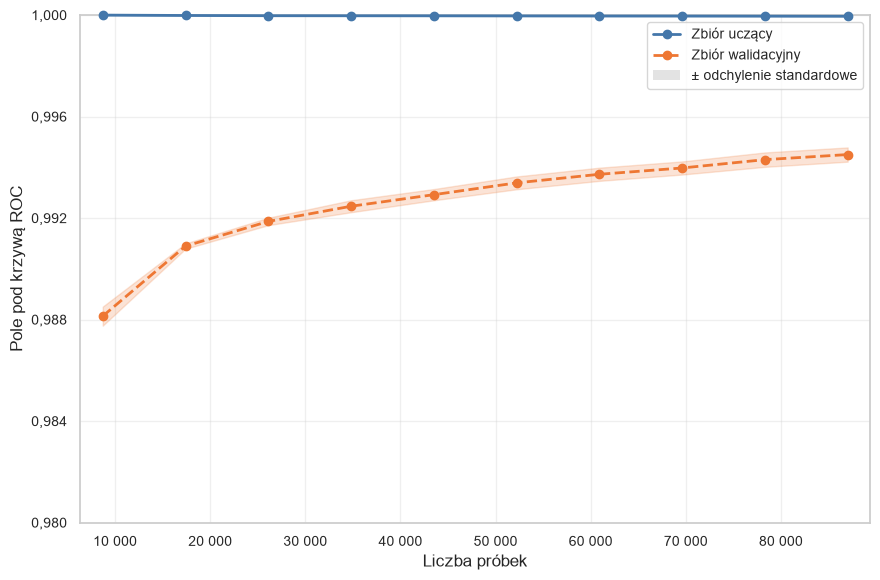

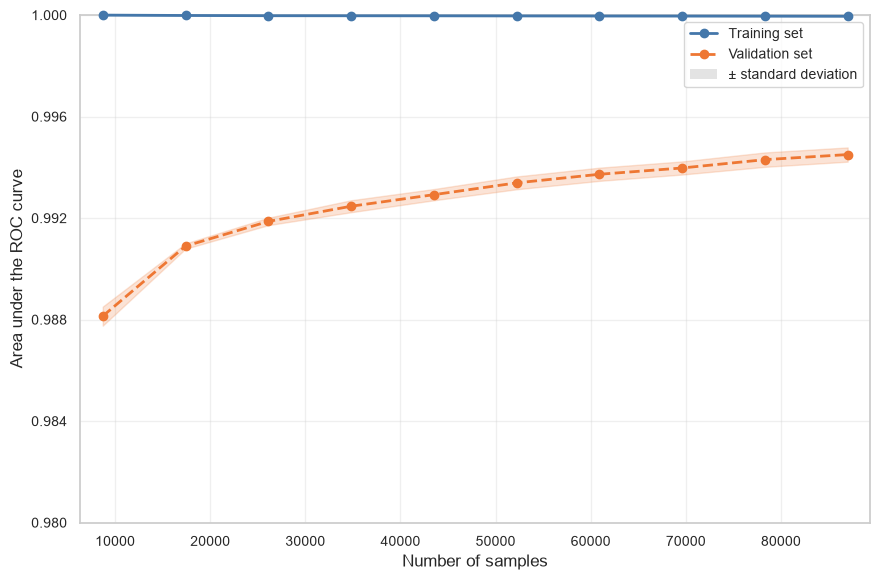

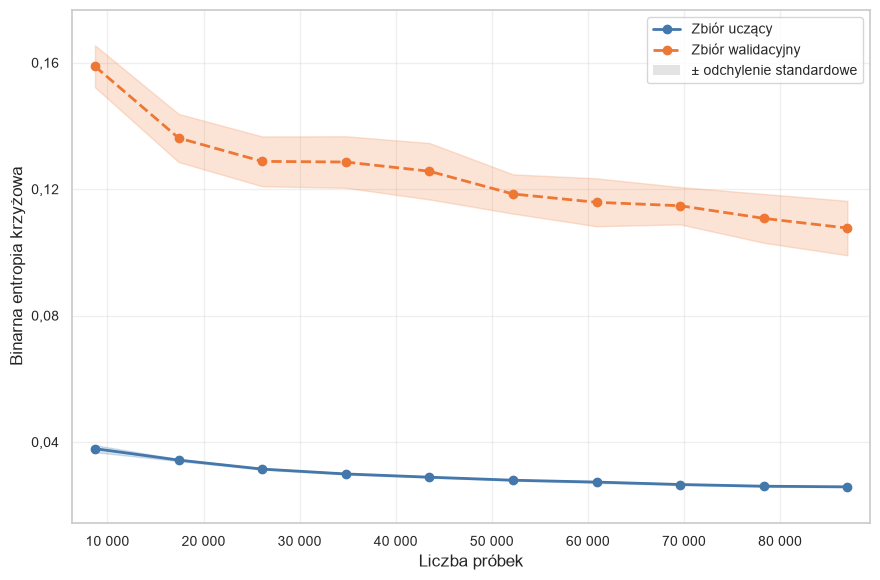

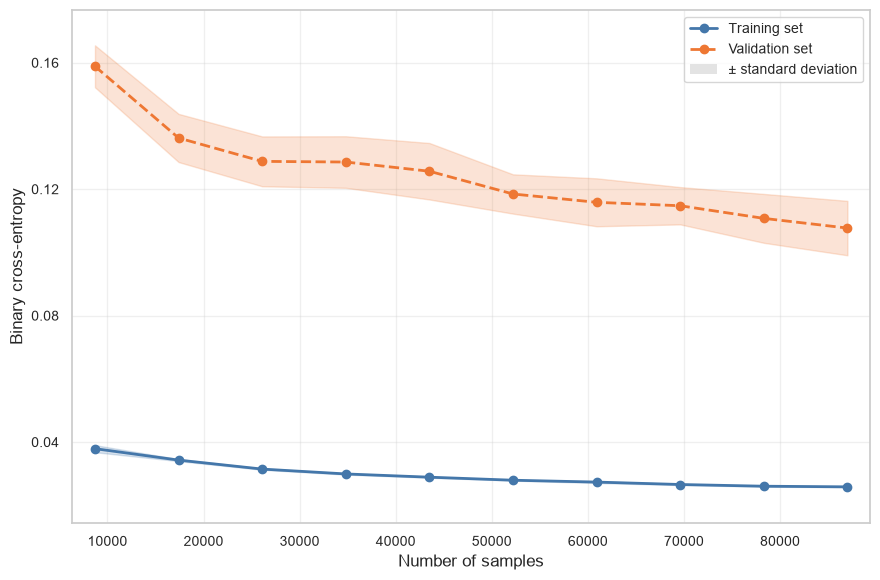

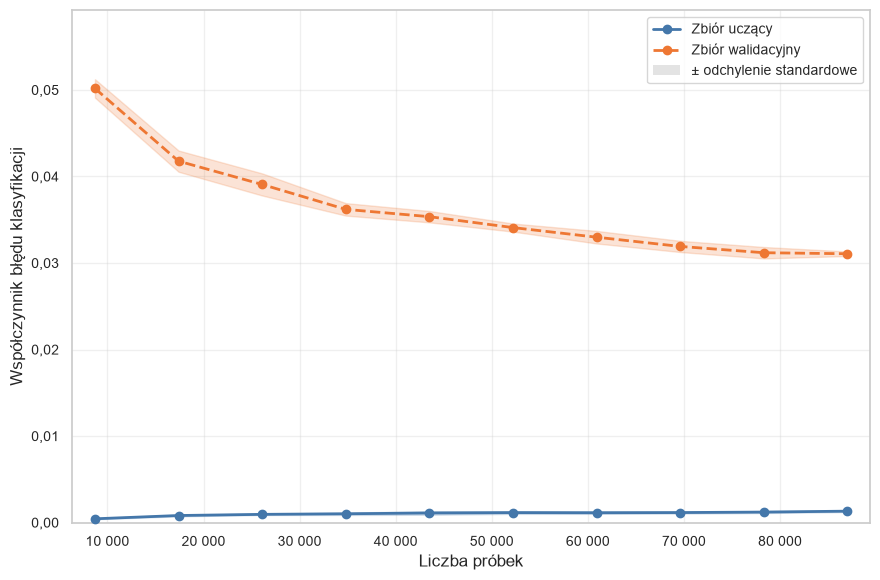

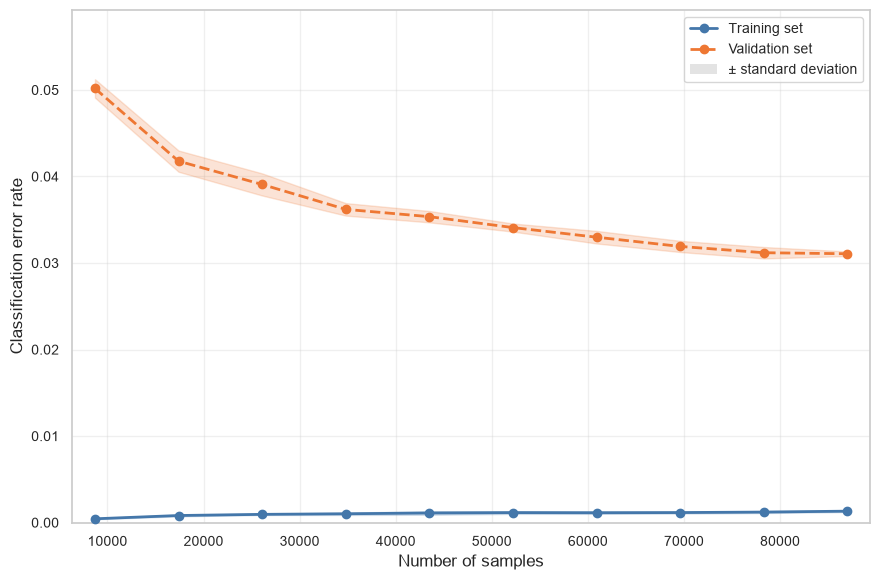

In [13]:
learning_results = {}
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = trained_models[dataset_name]['model']
    X_curve = train_test_data[dataset_name]['X_train']
    y_curve = train_test_data[dataset_name]['y_train']

    train_sizes, train_scores, validation_scores = learning_curve(
        model, train_test_data[dataset_name]['X_train'], train_test_data[dataset_name]['y_train'], cv=5, scoring='roc_auc', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_log_loss, validation_log_loss = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='neg_log_loss', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    _, train_accuracy, validation_accuracy = learning_curve(
        model, X_curve, y_curve, cv=5, scoring='accuracy', n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=42,
    )
    learning_results[dataset_name] = {
        'x': train_sizes,
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_log_loss_mean': (-train_log_loss).mean(axis=1),
        'train_log_loss_std': (-train_log_loss).std(axis=1),
        'validation_log_loss_mean': (-validation_log_loss).mean(axis=1),
        'validation_log_loss_std': (-validation_log_loss).std(axis=1),
        'train_error_rate_mean': (1.0 - train_accuracy).mean(axis=1),
        'train_error_rate_std': train_accuracy.std(axis=1),
        'validation_error_rate_mean': (1.0 - validation_accuracy).mean(axis=1),
        'validation_error_rate_std': validation_accuracy.std(axis=1),
    }

for dataset_name, values in learning_results.items():
    figure, _ = plot_score_curve(
        values['x'], values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Liczba próbek',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_log_loss_mean'], values['train_log_loss_std'],
        values['validation_log_loss_mean'], values['validation_log_loss_std'],
        x_label='Liczba próbek',
        y_label='Binarna entropia krzyżowa',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_bce_learning_curves.png')
    plt.show()

    figure, _ = plot_score_curve(
        values['x'], values['train_error_rate_mean'], values['train_error_rate_std'],
        values['validation_error_rate_mean'], values['validation_error_rate_std'],
        x_label='Liczba próbek',
        y_label='Współczynnik błędu klasyfikacji',
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_error_rate_learning_curves.png')
    plt.show()


## 7.3. Wpływ liczby drzew (n_estimators) na skuteczność modelu


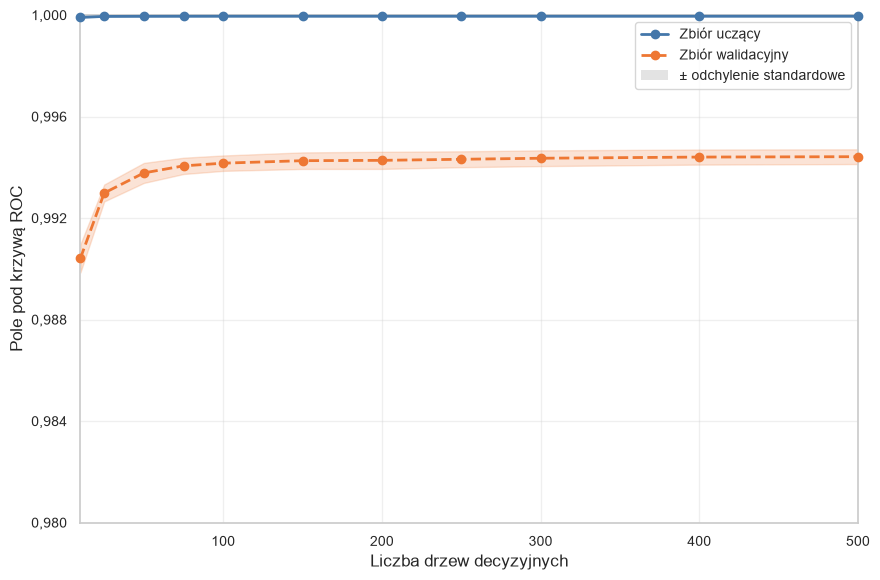

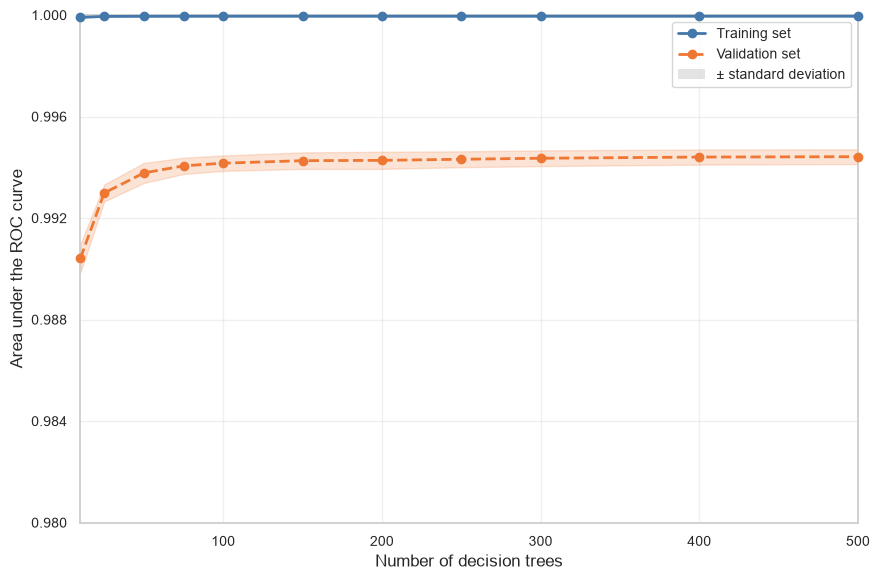

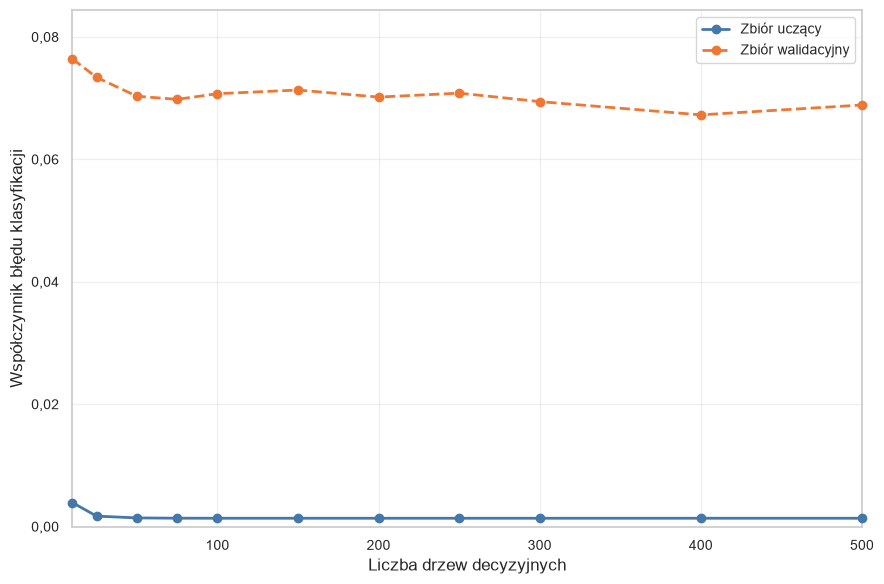

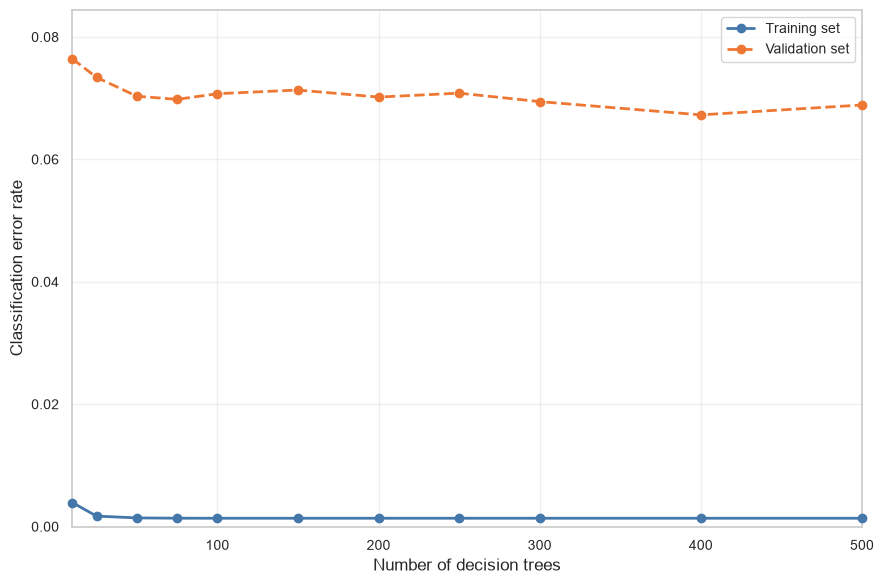

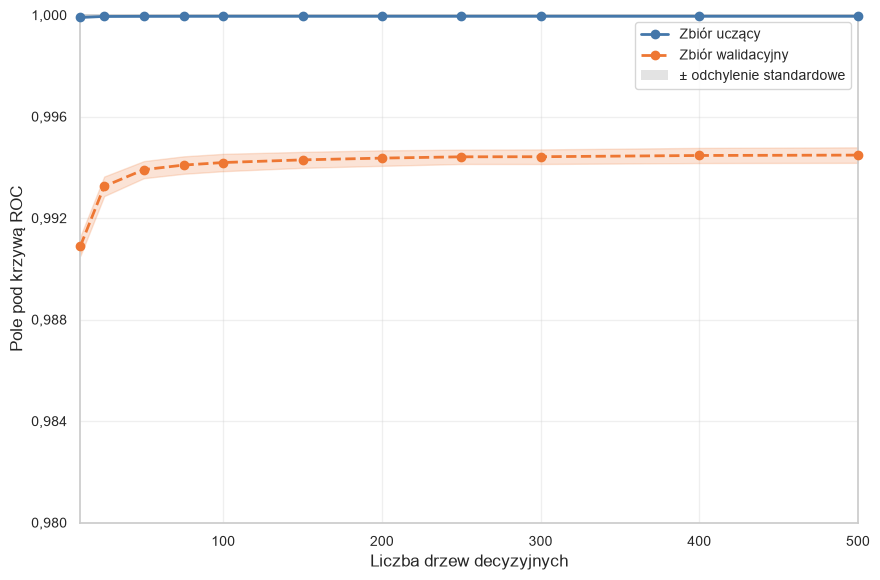

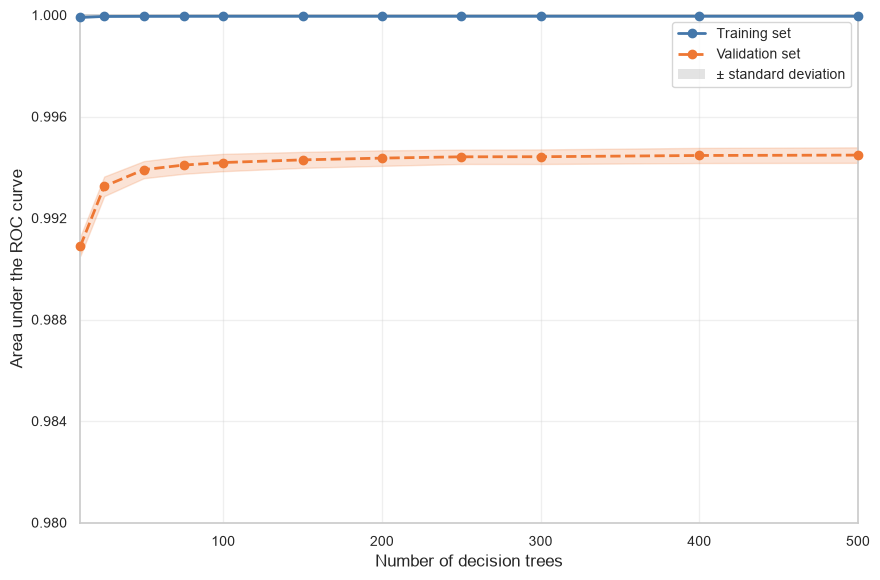

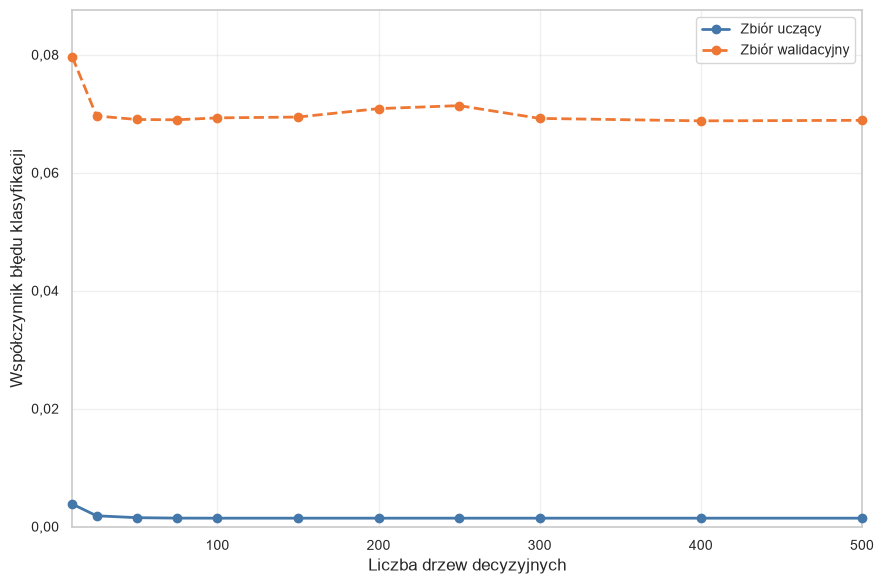

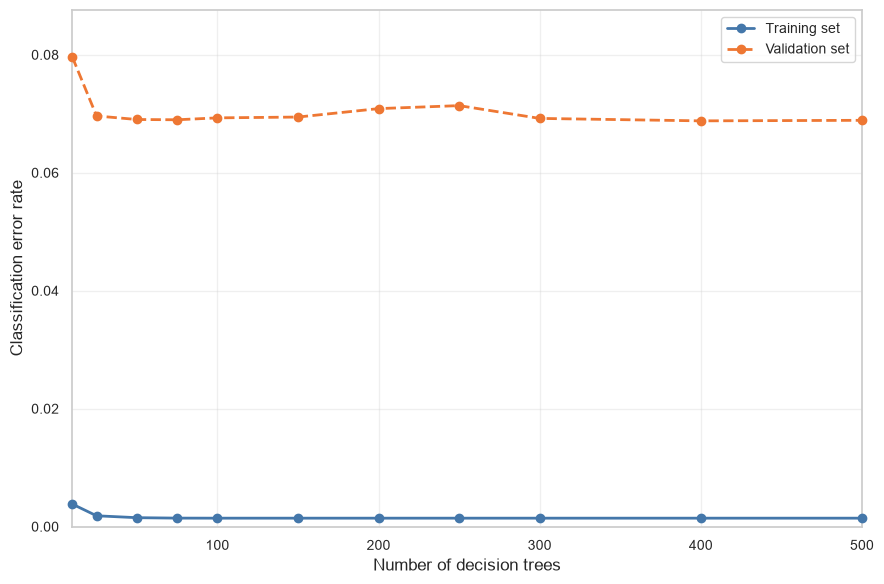

In [14]:
validation_results = {}
param_range = np.array([10, 25, 50, 75, 100, 150, 200, 250, 300, 400, 500])
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    X_curve = train_test_data[dataset_name]['X_train']
    y_curve = train_test_data[dataset_name]['y_train']
    X_val_curve = train_test_data[dataset_name]['X_val']
    y_val_curve = train_test_data[dataset_name]['y_val']

    model_base = RandomForestClassifier(random_state=42, n_jobs=-1)
    train_scores, validation_scores = validation_curve(
        model_base, X_curve, y_curve, param_name='n_estimators', param_range=param_range,
        cv=5, scoring='roc_auc', n_jobs=-1,
    )
    validation_results[dataset_name] = {
        'train_mean': train_scores.mean(axis=1),
        'train_std': train_scores.std(axis=1),
        'validation_mean': validation_scores.mean(axis=1),
        'validation_std': validation_scores.std(axis=1),
        'train_errors': [],
        'validation_errors': [],
    }
    for parameter_value in param_range:
        parameter_model = RandomForestClassifier(
            n_estimators=int(parameter_value), random_state=42, n_jobs=-1
        )
        parameter_model.fit(X_curve, y_curve)
        validation_results[dataset_name]['train_errors'].append(
            1.0 - accuracy_score(y_curve, parameter_model.predict(X_curve))
        )
        validation_results[dataset_name]['validation_errors'].append(
            1.0 - accuracy_score(y_val_curve, parameter_model.predict(X_val_curve))
        )

for dataset_name, values in validation_results.items():
    figure, _ = plot_score_curve(
        param_range, values['train_mean'], values['train_std'],
        values['validation_mean'], values['validation_std'],
        x_label='Liczba drzew decyzyjnych', logarithmic_x=False,
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_validation_curves.png')
    plt.show()
    figure, _ = plot_parameter_train_validation_error(
        param_range, values['train_errors'], values['validation_errors'],
        x_label='Liczba drzew decyzyjnych', logarithmic_x=False,
    )
    remove_dataset_figure(PLOTS_DIR, dataset_name, 'random_forest_parameter_train_validation_error.png')
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_parameter_train_validation_error.png')
    plt.show()


## 7.4. Tabela porównawcza wyników


In [15]:
comparison_df = pd.DataFrame({
    'Zbiór danych': ['Pełny zbiór', 'Zoptymalizowany zbiór'],
    'Dokładność': [evaluation_results['Pełny zbiór']['accuracy'], evaluation_results['Zoptymalizowany zbiór']['accuracy']],
    'Precyzja': [evaluation_results['Pełny zbiór']['precision'], evaluation_results['Zoptymalizowany zbiór']['precision']],
    'Czułość': [evaluation_results['Pełny zbiór']['recall'], evaluation_results['Zoptymalizowany zbiór']['recall']],
    'FPR (odsetek fałszywie dodatnich)': [evaluation_results['Pełny zbiór']['false_positive_rate'], evaluation_results['Zoptymalizowany zbiór']['false_positive_rate']],
    'Próg decyzyjny': [evaluation_results['Pełny zbiór']['decision_threshold'], evaluation_results['Zoptymalizowany zbiór']['decision_threshold']],
    'Miara F1': [evaluation_results['Pełny zbiór']['f1'], evaluation_results['Zoptymalizowany zbiór']['f1']],
    'AUC-ROC': [evaluation_results['Pełny zbiór']['auc_roc'], evaluation_results['Zoptymalizowany zbiór']['auc_roc']],
    'Średnia CV AUC': [evaluation_results['Pełny zbiór']['cv_mean'], evaluation_results['Zoptymalizowany zbiór']['cv_mean']],
    'Odchylenie CV AUC': [evaluation_results['Pełny zbiór']['cv_std'], evaluation_results['Zoptymalizowany zbiór']['cv_std']],
    'Czas uczenia (s)': [trained_models['Pełny zbiór']['training_time'], trained_models['Zoptymalizowany zbiór']['training_time']],
    'Liczba cech': [data_splits['Pełny zbiór']['feature_count'], data_splits['Zoptymalizowany zbiór']['feature_count']],
    'Średnie CPU [%]': [resource_stats[name]['stats']['cpu']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalne CPU [%]': [resource_stats[name]['stats']['cpu']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Średni RAM [GB]': [resource_stats[name]['stats']['ram']['mean'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Maksymalny RAM [GB]': [resource_stats[name]['stats']['ram']['max'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']],
    'Próbki pomiarowe': [resource_stats[name]['stats']['samples'] for name in ['Pełny zbiór', 'Zoptymalizowany zbiór']]
})

comparison_path = backend_root.parent / 'results' / 'url_corpus' / 'model_comparisons' / 'random_forest_comparison.csv'
comparison_path.parent.mkdir(parents=True, exist_ok=True)
comparison_df.to_csv(comparison_path, index=False)
print(f"✓ Porównanie zapisane: {comparison_path}")
print("\nTabela porównawcza:")
print(comparison_df.to_string(index=False))

✓ Porównanie zapisane: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/model_comparisons/random_forest_comparison.csv

Tabela porównawcza:
         Zbiór danych  Dokładność  Precyzja  Czułość  FPR (odsetek fałszywie dodatnich)  Próg decyzyjny  Miara F1  AUC-ROC  Średnia CV AUC  Odchylenie CV AUC  Czas uczenia (s)  Liczba cech  Średnie CPU [%]  Maksymalne CPU [%]  Średni RAM [GB]  Maksymalny RAM [GB]  Próbki pomiarowe
          Pełny zbiór    0.901143  0.974111 0.824190                           0.021905        0.600087  0.892901 0.979326        0.994415           0.000309          4.463664          110        71.934878          100.758443         0.653620             0.826111                70
Zoptymalizowany zbiór    0.903095  0.975402 0.827048                           0.020857        0.606667  0.895119 0.980629        0.994447           0.000252          2.893810           47        87.825618          100.614418         0.505566             0.

## 7.5. Ważność cech w obu modelach


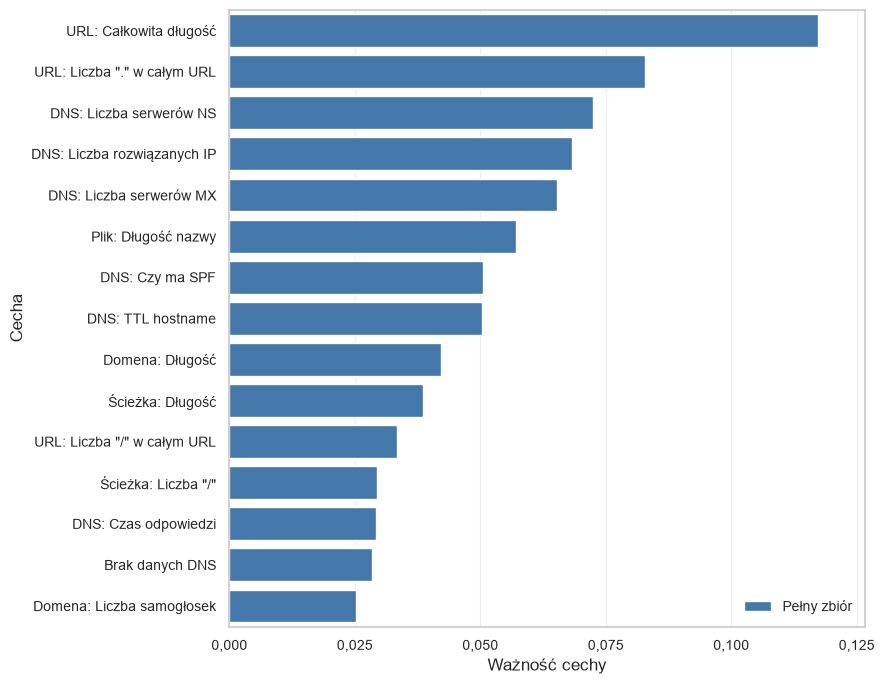

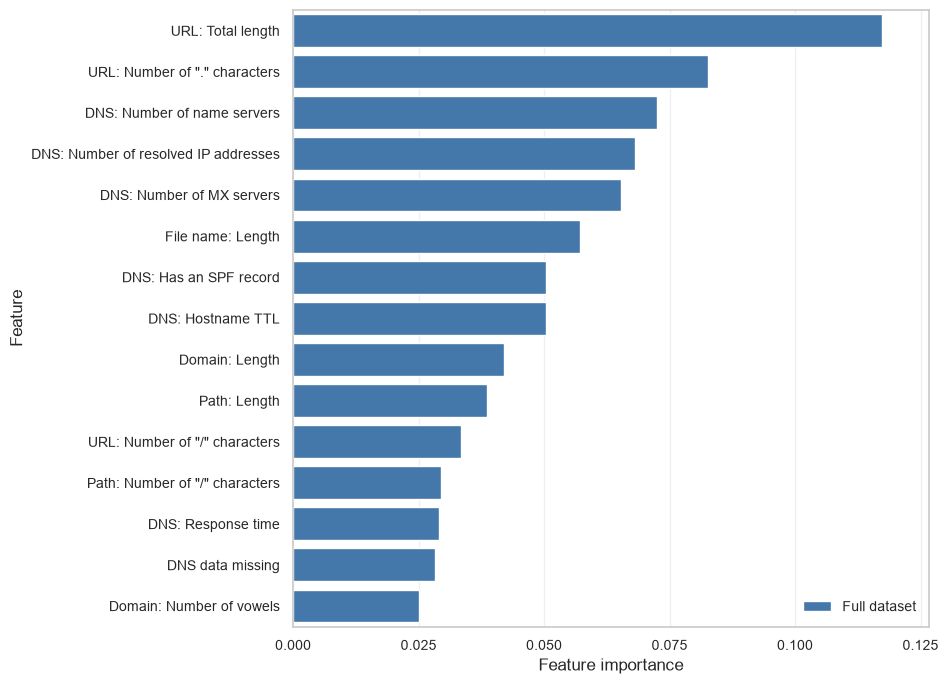

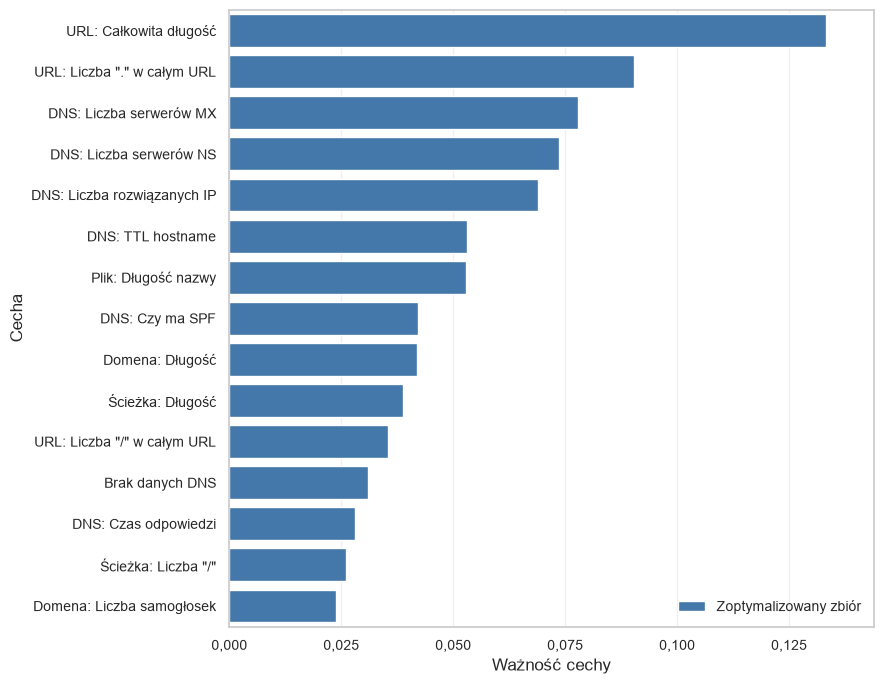

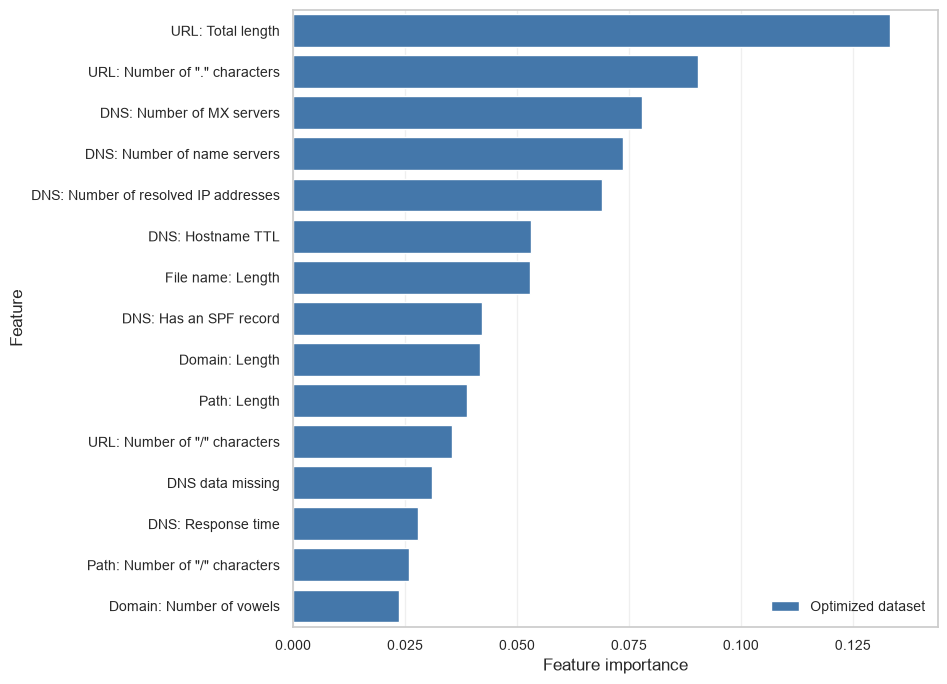

In [16]:
for dataset_name in ['Pełny zbiór', 'Zoptymalizowany zbiór']:
    model = trained_models[dataset_name]['model']
    X_features = train_test_data[dataset_name]['X_train']
    feature_importance = pd.DataFrame({
        'Cecha': [get_readable_name(column) for column in X_features.columns],
        'Ważność': model.feature_importances_,
    }).sort_values('Ważność', ascending=False).head(15)
    figure, _ = plot_feature_ranking(
        feature_importance, dataset_name, x_column='Ważność', x_label='Ważność cechy'
    )
    save_dataset_figure(figure, PLOTS_DIR, dataset_name, 'random_forest_feature_importance.png')
    plt.show()


## 8. Zapis modelu


In [17]:
for dataset_name, model_data in trained_models.items():
    model = model_data['model']

    if 'Pełny' in dataset_name:
        model_filename = f'{MODELS_DIR}/random_forest_full_url_corpus.pkl'
    else:
        model_filename = f'{MODELS_DIR}/random_forest_optimized_url_corpus.pkl'

    model_save_data = {
        'model': model,
        'scaler': None,
        'feature_names': train_test_data[dataset_name]['X_train'].columns.tolist(),
        'best_params': model_data['params'],
        'decision_threshold': evaluation_results[dataset_name]['decision_threshold'],
        'threshold_calibration': evaluation_results[dataset_name]['threshold_calibration'],
        'metrics': {
            'accuracy': evaluation_results[dataset_name]['accuracy'],
            'precision': evaluation_results[dataset_name]['precision'],
            'recall': evaluation_results[dataset_name]['recall'],
            'f1': evaluation_results[dataset_name]['f1'],
            'auc_roc': evaluation_results[dataset_name]['auc_roc'],
            'cv_auc_mean': evaluation_results[dataset_name]['cv_mean'],
            'cv_auc_std': evaluation_results[dataset_name]['cv_std']
        }
    }

    with open(model_filename, 'wb') as f:
        pickle.dump(model_save_data, f)

    print(f"✅ {dataset_name}:")
    print(f"   Model zapisany: {model_filename}")
    print(f"   Parametry: {model_data['params']}")
    print(f"   Wynik funkcji kalibracyjnej: {model_data['cv_score']:.4f}")
    print(f"   Test ROC-AUC: {evaluation_results[dataset_name]['auc_roc']:.4f}")
    print()

print("="*80)
print("PODSUMOWANIE KOŃCOWE")
print("="*80)
print(f"\nPrzeszkolono i zapisano {len(trained_models)} modele Random Forest:")
print(f"  1. Model na pełnym zbiorze: {data_splits['Pełny zbiór']['feature_count']} cech")
print(f"  2. Model na zoptymalizowanym zbiorze: {data_splits['Zoptymalizowany zbiór']['feature_count']} cech")
print(f"\nWizualizacje zapisane w: {PLOTS_DIR}/")
print(f"Modele zapisane w: {MODELS_DIR}/")


✅ Pełny zbiór:
   Model zapisany: ../models/random_forest/random_forest_full_url_corpus.pkl
   Parametry: {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
   Wynik funkcji kalibracyjnej: 1.2230
   Test ROC-AUC: 0.9793



✅ Zoptymalizowany zbiór:
   Model zapisany: ../models/random_forest/random_forest_optimized_url_corpus.pkl
   Parametry: {'class_weight': 'balanced', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
   Wynik funkcji kalibracyjnej: 1.2229
   Test ROC-AUC: 0.9806

PODSUMOWANIE KOŃCOWE

Przeszkolono i zapisano 2 modele Random Forest:
  1. Model na pełnym zbiorze: 110 cech
  2. Model na zoptymalizowanym zbiorze: 47 cech

Wizualizacje zapisane w: /Users/maksymiliansowula/Documents/Studia/Magisterka/PhisingDetector/results/url_corpus/plots/random_forest/
Modele zapisane w: ../models/random_forest/
